# Loan Portfolio and Default Risk Analysis

**Sijie Hu** · November 2023 · Python (pandas, Matplotlib, Seaborn, scikit-learn)

A case study for a fictional lender, "Amalgamated Bank Corp (ABC)", using 307,511 loan applications from the public Home Credit Default Risk dataset.

**What this notebook does**

1. Cleans the data: handles missing values column by column and documents why.
2. Removes outliers using box plots, the 1.5 × IQR rule and percentile checks, keeping 301,991 of 307,511 records (98.2%).
3. Profiles the portfolio for senior management: total exposure, default rate, customer demographics.
4. Compares customers with payment difficulties against the rest.
5. Fits a baseline logistic regression to show how default probability could be predicted.

**Headline numbers**

- Total credit outstanding: about $179.8 billion across 301,991 loans
- Loans with payment difficulties: 24,441, which is 8.09% by count and 7.56% by amount
- Baseline model: 70.9% in-sample accuracy; it catches about one in three problem loans

## Business brief

ABC's management has a file of more than 300,000 loans and a data dictionary, but little understanding of who their customers are or what the data can tell them. The brief has five parts:

1. **Cleanse.** Find missing data and choose a strategy for each column, with reasons.
2. **Outliers.** Find and remove outliers, showing the work.
3. **Who are our clients?** Total loans outstanding, how much is in default or late (amount and percent), plus three customer demographics. Charts must be readable at a summary level for senior management.
4. **Who has trouble repaying?** Three visualizations of what distinguishes customers in default or late.
5. **Regression.** Prepare the data, run a regression, and show scoring and a confusion matrix. The brief asks for the model to be fit on the full dataset, without a train/test split.

## Table of Contents

[0. Libraries](#0.-Libraries)  
[1. The base](#1.-The-base)  
[2. Cleanse](#2.-Cleanse)  
[3. Outliers](#3.-Outliers)  
[4. Analysis](#4.-Analysis)  
[5. Regression](#5.-Regression)

## 0. Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

## 1. The base

In [3]:
df = pd.read_csv('application_train.csv')

## 2. Cleanse

In [4]:
# check basics
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Data columns (total 37 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   SK_ID_CURR                   307511 non-null  int64  
 1   Unnamed: 1                   0 non-null       float64
 2   NAME_CONTRACT_TYPE           307511 non-null  object 
 3   CODE_GENDER                  307511 non-null  object 
 4   FLAG_OWN_CAR                 307511 non-null  object 
 5   FLAG_OWN_REALTY              307511 non-null  object 
 6   CNT_CHILDREN                 307511 non-null  int64  
 7   AMT_INCOME_TOTAL             307511 non-null  float64
 8   AMT_CREDIT                   307511 non-null  float64
 9   AMT_ANNUITY                  307499 non-null  float64
 10  AMT_GOODS_PRICE              307233 non-null  float64
 11  NAME_TYPE_SUITE              306219 non-null  object 
 12  NAME_INCOME_TYPE             307511 non-null  object 
 13 

In [5]:
df.head()

,SK_ID_CURR,Unnamed: 1,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,TARGET
0,100002,NaN,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,Laborers,1.0,0,0,0,0,0,0,Business Entity Type 3,1
1,100003,NaN,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,Core staff,2.0,0,0,0,0,0,0,School,0
2,100004,NaN,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,Laborers,1.0,0,0,0,0,0,0,Government,0
3,100006,NaN,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,Laborers,2.0,0,0,0,0,0,0,Business Entity Type 3,0
4,100007,NaN,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,Core staff,1.0,0,0,0,0,1,1,Religion,0


In [6]:
# check if any column is totally empty
def delete_empty_column(df):
    del_column = []
    
    for i in df.columns:
        if i.find('Unnamed') >= 0:
            del_column.append(i)
    
    dfnew = df.drop(columns=del_column)

    return dfnew

# delete
df = delete_empty_column(df)
df.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,TARGET
0,100002,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,...,Laborers,1.0,0,0,0,0,0,0,Business Entity Type 3,1
1,100003,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,...,Core staff,2.0,0,0,0,0,0,0,School,0
2,100004,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,...,Laborers,1.0,0,0,0,0,0,0,Government,0
3,100006,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,...,Laborers,2.0,0,0,0,0,0,0,Business Entity Type 3,0
4,100007,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,...,Core staff,1.0,0,0,0,0,1,1,Religion,0


In [7]:
# check if there is any NaN in any column, and how many
# turns out we have some columns with NaN
df.isna().sum()

SK_ID_CURR                          0
NAME_CONTRACT_TYPE                  0
CODE_GENDER                         0
FLAG_OWN_CAR                        0
FLAG_OWN_REALTY                     0
CNT_CHILDREN                        0
AMT_INCOME_TOTAL                    0
AMT_CREDIT                          0
AMT_ANNUITY                        12
AMT_GOODS_PRICE                   278
NAME_TYPE_SUITE                  1292
NAME_INCOME_TYPE                    0
NAME_EDUCATION_TYPE                 0
NAME_FAMILY_STATUS                  0
NAME_HOUSING_TYPE                   0
DAYS_BIRTH                          0
DAYS_EMPLOYED                       0
DAYS_REGISTRATION                   0
DAYS_ID_PUBLISH                     0
OWN_CAR_AGE                    202929
FLAG_MOBIL                          0
FLAG_EMP_PHONE                      0
FLAG_WORK_PHONE                     0
FLAG_CONT_MOBILE                    0
FLAG_PHONE                          0
FLAG_EMAIL                          0
OCCUPATION_T

In [8]:
# deal with AMT_ANNUITY, AMT_GOODS_PRICE, NAME_TYPE_SUITE, OWN_CAR_AGE, OCCUPATION_TYPE, CNT_FAM_MEMBERS

# NAME_TYPE_SUITE
# Who was accompanying client when he was applying for the loan
# 1292, too many to drop. replace with 'Unknown'
# the value is not used in the column, same data type - str
df['NAME_TYPE_SUITE'].fillna('Unknown', inplace=True)

# OCCUPATION_TYPE
# What kind of occupation does the client have
# 96391, a lot of blanks
# replace blank with 'Unknown'. it is not used in there. same data type - str
df['OCCUPATION_TYPE'].fillna('Unknown', inplace=True)

# OWN_CAR_AGE
# Age of client's car
# 0 is already there
# replace blank with -1. same data type - int. easy to find.
# basically means 'data not available' to us
df['OWN_CAR_AGE'].fillna(-1, inplace=True)

# AMT_ANNUITY, AMT_GOODS_PRICE, CNT_FAM_MEMBERS
# 12, 278, 2 not a significant number of records
# also does not make sense to be empty - loan amount is essential
# does not make sense not having it
# just drop them
df.dropna(inplace=True)

# check again
# all NaN are gone
df.isna().sum()

SK_ID_CURR                     0
NAME_CONTRACT_TYPE             0
CODE_GENDER                    0
FLAG_OWN_CAR                   0
FLAG_OWN_REALTY                0
CNT_CHILDREN                   0
AMT_INCOME_TOTAL               0
AMT_CREDIT                     0
AMT_ANNUITY                    0
AMT_GOODS_PRICE                0
NAME_TYPE_SUITE                0
NAME_INCOME_TYPE               0
NAME_EDUCATION_TYPE            0
NAME_FAMILY_STATUS             0
NAME_HOUSING_TYPE              0
DAYS_BIRTH                     0
DAYS_EMPLOYED                  0
DAYS_REGISTRATION              0
DAYS_ID_PUBLISH                0
OWN_CAR_AGE                    0
FLAG_MOBIL                     0
FLAG_EMP_PHONE                 0
FLAG_WORK_PHONE                0
FLAG_CONT_MOBILE               0
FLAG_PHONE                     0
FLAG_EMAIL                     0
OCCUPATION_TYPE                0
CNT_FAM_MEMBERS                0
REG_REGION_NOT_LIVE_REGION     0
REG_REGION_NOT_WORK_REGION     0
LIVE_REGIO

## 3. Outliers

### General info

In [9]:
# 307221 is the total records at this point
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 307221 entries, 0 to 307510
Data columns (total 36 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   SK_ID_CURR                   307221 non-null  int64  
 1   NAME_CONTRACT_TYPE           307221 non-null  object 
 2   CODE_GENDER                  307221 non-null  object 
 3   FLAG_OWN_CAR                 307221 non-null  object 
 4   FLAG_OWN_REALTY              307221 non-null  object 
 5   CNT_CHILDREN                 307221 non-null  int64  
 6   AMT_INCOME_TOTAL             307221 non-null  float64
 7   AMT_CREDIT                   307221 non-null  float64
 8   AMT_ANNUITY                  307221 non-null  float64
 9   AMT_GOODS_PRICE              307221 non-null  float64
 10  NAME_TYPE_SUITE              307221 non-null  object 
 11  NAME_INCOME_TYPE             307221 non-null  object 
 12  NAME_EDUCATION_TYPE          307221 non-null  object 
 13  NAME

In [10]:
# it is good that SK_ID_CURR has all values unique
# theoretically SK_ID_CURR is the PK in database

# to deal with the outliers
# we deal with columns that have a lot of unique values
# the columns that have 2 unique values are likely binary columns
# will convert them to 0/1 if they are not
# later in the regression process
df.nunique()

SK_ID_CURR                     307221
NAME_CONTRACT_TYPE                  2
CODE_GENDER                         3
FLAG_OWN_CAR                        2
FLAG_OWN_REALTY                     2
CNT_CHILDREN                       15
AMT_INCOME_TOTAL                 2547
AMT_CREDIT                       5603
AMT_ANNUITY                     13672
AMT_GOODS_PRICE                  1002
NAME_TYPE_SUITE                     8
NAME_INCOME_TYPE                    8
NAME_EDUCATION_TYPE                 5
NAME_FAMILY_STATUS                  5
NAME_HOUSING_TYPE                   6
DAYS_BIRTH                      17460
DAYS_EMPLOYED                   12572
DAYS_REGISTRATION               15688
DAYS_ID_PUBLISH                  6168
OWN_CAR_AGE                        63
FLAG_MOBIL                          2
FLAG_EMP_PHONE                      2
FLAG_WORK_PHONE                     2
FLAG_CONT_MOBILE                    2
FLAG_PHONE                          2
FLAG_EMAIL                          2
OCCUPATION_T

### CNT_CHILDREN

<Axes: xlabel='SK_ID_CURR', ylabel='CNT_CHILDREN'>

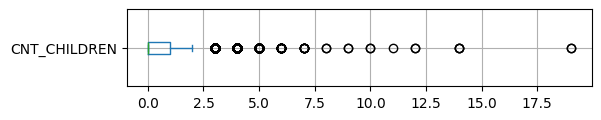

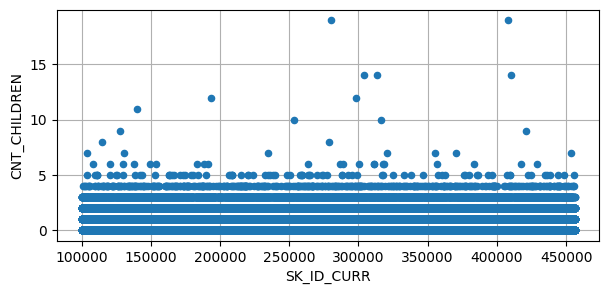

In [11]:
# not very common to have >= 7 children
df.plot.box(column='CNT_CHILDREN', vert=False, figsize=(6,1), zorder=2, grid=True)
df.plot.scatter(x='SK_ID_CURR', y='CNT_CHILDREN', figsize=(7,3), zorder=2, grid=True)

In [12]:
# seems ok to remove the top 25%, but let's investigate moretop
# q75 is 1 child
df['CNT_CHILDREN'].describe()

count    307221.000000
mean          0.416977
std           0.722047
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          19.000000
Name: CNT_CHILDREN, dtype: float64

In [13]:
# let's try to invent function that will potentially work on all columns
# first find outliers, confirm the number and percentage
# combine with the box and scatter plot analysis
# then another function to remove the outliers

# all boundaries are exclusive
def find_outlier(column, q):
    # regular IQR analysis
    Q1 = column.quantile(0.25)
    Q3 = column.quantile(0.75)
    IQR = Q3 - Q1
    
    below = Q1 - 1.5 * IQR
    above = Q3 + 1.5 * IQR

    below_count = len(column[column < below])
    above_count = len(column[column > above])

    # custom Q analysis
    qresult = column.quantile(q)
    lentop = len(column[column > qresult])
    lentotal = len(column)
    
    percent = lentop / lentotal * 100
    percent_str = f'{percent:.2f}%'

    # report
    print('Report:\n'
          f'1.5 IQR below is: {below}, 1.5 IQR above is: {above}\n'
          f'below count: {below_count}, above count: {above_count}\n'
          f'q{q*100} is: {qresult}, count: {lentop}, percent: {percent_str}\n'
          f'total: {lentotal}')
    
    return None

find_outlier(df['CNT_CHILDREN'], 0.99)

Report:
1.5 IQR below is: -1.5, 1.5 IQR above is: 2.5
below count: 0, above count: 4264
q99.0 is: 3.0, count: 553, percent: 0.18%
total: 307221


In [14]:
# q99 is 3
# seems ok to remove >= 5, based on the plot and the quantile analysis
# those 15+ children may be input mistakes
# it is very possible to have 4 children
# and the plot seems dense enough, so keep them
# all in all, we keep most of the records

# the method we use:
# 1. common sense
# 2. 1.5 IQR method
# 3. try not to delete too many records

# let's define another function so we can reuse it
# it also prints how many we have removed
def remove_outlier(df, column, point):
    print(f'records removed: {len(df[df[column] > point])}')
    
    dfnew = df[df[column] <= point]
    
    return dfnew

# the beauty is we can keep running this function
# and the result will not decrease
# gone is gone
# no risk of running the cells again
# the cutting point - 5 here - is inclusive
df = remove_outlier(df, 'CNT_CHILDREN', 4)

records removed: 126


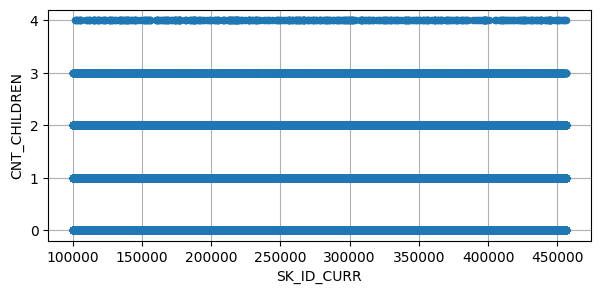

307095

In [15]:
# only removed 126 records
# check the result
df.plot.scatter(x='SK_ID_CURR', y='CNT_CHILDREN', figsize=(7,3), zorder=2, grid=True)
plt.show()

len(df)

In [16]:
# 307095 now compared to 307221 where we started
# let's continue

### AMT_INCOME_TOTAL

<Axes: xlabel='SK_ID_CURR', ylabel='AMT_INCOME_TOTAL'>

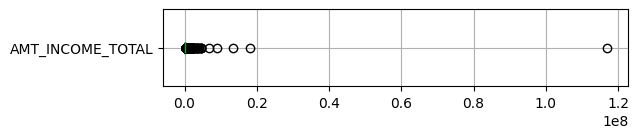

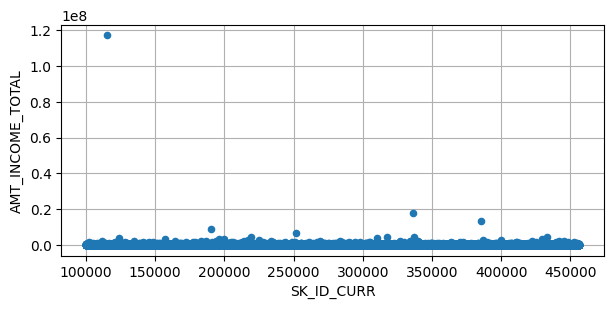

In [17]:
# check income total
# the 120 million income value is a clear candidate for removal
df.plot.box(column='AMT_INCOME_TOTAL', vert=False, figsize=(6,1), zorder=2, grid=True)
df.plot.scatter(x='SK_ID_CURR', y='AMT_INCOME_TOTAL', figsize=(7,3), zorder=2, grid=True)

In [18]:
# use our function
find_outlier(df['AMT_INCOME_TOTAL'], 0.99)

Report:
1.5 IQR below is: -22500.0, 1.5 IQR above is: 337500.0
below count: 0, above count: 14024
q99.0 is: 472500.0, count: 3011, percent: 0.98%
total: 307095


In [19]:
# 3011 is a little too much, maybe
# try again
find_outlier(df['AMT_INCOME_TOTAL'], 0.999)

Report:
1.5 IQR below is: -22500.0, 1.5 IQR above is: 337500.0
below count: 0, above count: 14024
q99.9 is: 900000.0, count: 278, percent: 0.09%
total: 307095


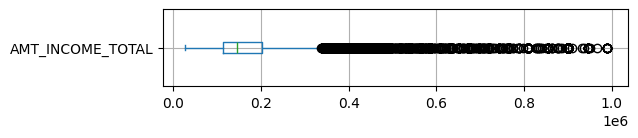

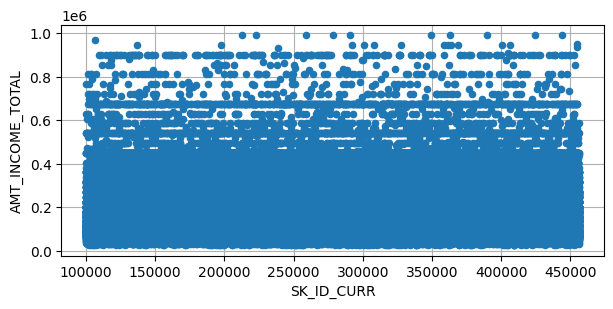

306845

In [20]:
# so one million seems to be the cut point
# but check those records before removal
# because they may have significant amount of loans if they have that much income

# quick check of applicants with income under 1 mil
# probably can still remove some of the top ones
# after all, annual income of 1 mil is very very rich
df_less_mil = df[df['AMT_INCOME_TOTAL'] <= 1000000]

df_less_mil.plot.box(column='AMT_INCOME_TOTAL', vert=False, figsize=(6,1), zorder=2, grid=True)
df_less_mil.plot.scatter(x='SK_ID_CURR', y='AMT_INCOME_TOTAL', figsize=(7,3), zorder=2, grid=True)
plt.show()

len(df_less_mil)

#### 1. the millionaire anaysis

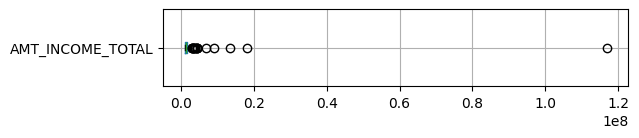

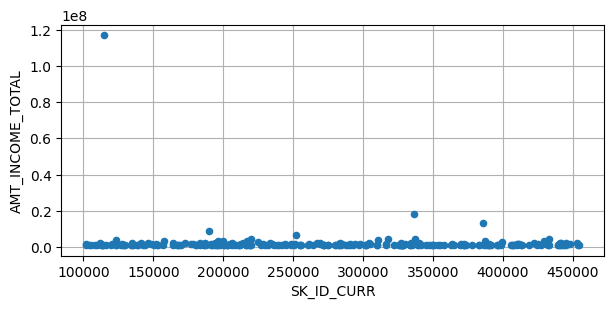

250

In [21]:
df_more_mil = df[df['AMT_INCOME_TOTAL'] > 1000000]

# same as plot.box, a little less typing
# seems fine to omit the zorder and grid params
# we will keep optimizing the code when we proceeed
df_more_mil.boxplot('AMT_INCOME_TOTAL', vert=False, figsize=(6,1))
df_more_mil.plot.scatter(x='SK_ID_CURR', y='AMT_INCOME_TOTAL', figsize=(7,3), zorder=2, grid=True)
plt.show()

len(df_more_mil)

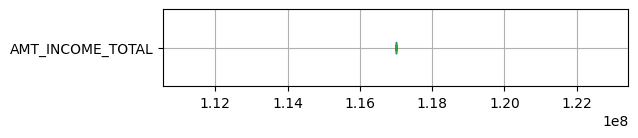

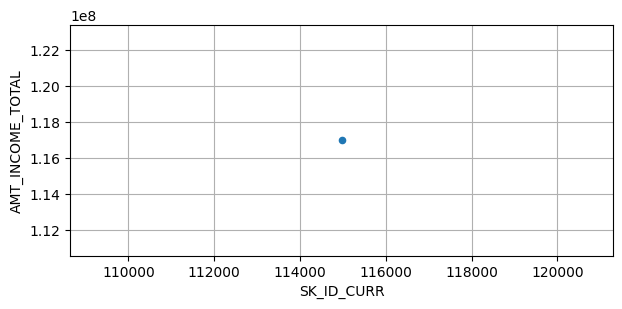

1

In [22]:
# check the 120 mil record
df_temp = df[df['AMT_INCOME_TOTAL'] > 110000000]

df_temp.boxplot('AMT_INCOME_TOTAL', vert=False, figsize=(6,1))
df_temp.plot.scatter(x='SK_ID_CURR', y='AMT_INCOME_TOTAL', figsize=(7,3), zorder=2, grid=True)
plt.show()

len(df_temp)

In [23]:
# just 1 applicant
# check other information about him/her
# the applicant is female

df_temp

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,TARGET
12840,114967,Cash loans,F,N,Y,1,117000000.0,562491.0,26194.5,454500.0,...,Laborers,3.0,0,0,0,0,0,0,Business Entity Type 3,1


In [24]:
# she just sits in the middle, in terms of the stats
# so the income must be a typo
# will drop
df[['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']].describe()

,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
count,3.070950e+05,307095.000000,3.070950e+05
mean,5.993361e+05,27120.611972,5.384209e+05
std,4.025330e+05,14492.454729,3.694647e+05
min,4.500000e+04,1615.500000,4.050000e+04
25%,2.700000e+05,16551.000000,2.385000e+05
50%,5.146020e+05,24916.500000,4.500000e+05
75%,8.086500e+05,34596.000000,6.795000e+05
max,4.050000e+06,258025.500000,4.050000e+06


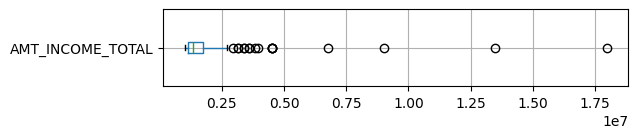

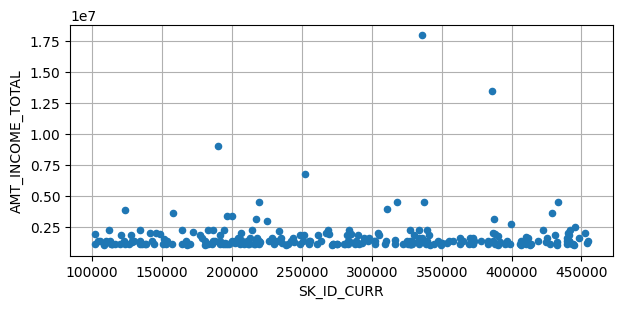

249

In [25]:
# check other millionaires
df_more_mil = df[ (df['AMT_INCOME_TOTAL'] > 1000000) & (df['AMT_INCOME_TOTAL'] < 110000000) ]

df_more_mil.boxplot('AMT_INCOME_TOTAL', vert=False, figsize=(6,1))
df_more_mil.plot.scatter(x='SK_ID_CURR', y='AMT_INCOME_TOTAL', figsize=(7,3), zorder=2, grid=True)
plt.show()

len(df_more_mil)

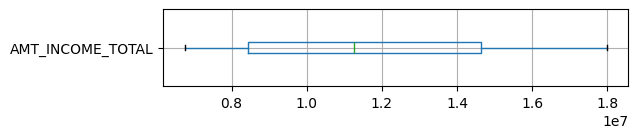

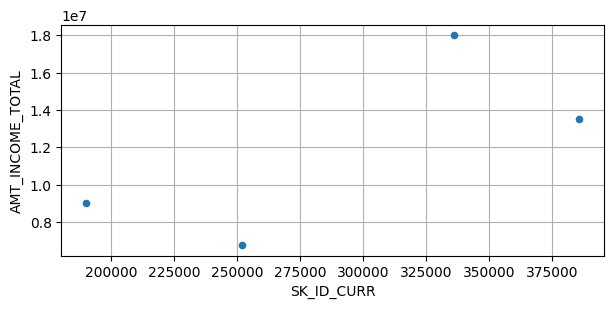

4

In [26]:
# get details about the top 4 dots

df_temp2 = df_more_mil[df_more_mil['AMT_INCOME_TOTAL'] > 0.6*10000000]

df_temp2.boxplot('AMT_INCOME_TOTAL', vert=False, figsize=(6,1))
df_temp2.plot.scatter(x='SK_ID_CURR', y='AMT_INCOME_TOTAL', figsize=(7,3), zorder=2, grid=True)
plt.show()

len(df_temp2)

In [27]:
# 4 dots are 4 people exactly
# check the details

df_temp2

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,TARGET
77768,190160,Cash loans,F,Y,N,0,9000000.0,1431531.0,132601.5,1377000.0,...,Managers,2.0,0,0,0,0,0,0,Business Entity Type 1,0
131127,252084,Cash loans,M,Y,N,0,6750000.0,790830.0,52978.5,675000.0,...,Laborers,2.0,0,1,1,0,1,1,Transport: type 4,0
203693,336147,Cash loans,M,Y,Y,2,18000090.0,675000.0,69295.5,675000.0,...,Unknown,4.0,0,0,0,0,0,0,Business Entity Type 3,0
246858,385674,Cash loans,M,Y,Y,0,13500000.0,1400503.5,130945.5,1368000.0,...,Unknown,2.0,0,0,0,0,0,0,Business Entity Type 3,0


In [28]:
# compare to the average
df[['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']].describe()

,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
count,3.070950e+05,307095.000000,3.070950e+05
mean,5.993361e+05,27120.611972,5.384209e+05
std,4.025330e+05,14492.454729,3.694647e+05
min,4.500000e+04,1615.500000,4.050000e+04
25%,2.700000e+05,16551.000000,2.385000e+05
50%,5.146020e+05,24916.500000,4.500000e+05
75%,8.086500e+05,34596.000000,6.795000e+05
max,4.050000e+06,258025.500000,4.050000e+06


In [29]:
# check the millionaire group's total loan amount
# compared to the bank's total loan amount
# see if the percentage is significant
df_more_mil['AMT_CREDIT'].sum() / ( df_more_mil['AMT_CREDIT'].sum() + \
                                   df_less_mil['AMT_CREDIT'].sum() ) * 100

0.1574627552598572

In [30]:
len(df_more_mil) / ( len(df_more_mil) + len(df_less_mil) ) * 100

0.08108266524256416

records removed: 250


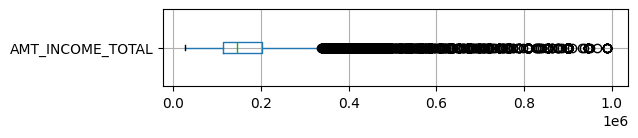

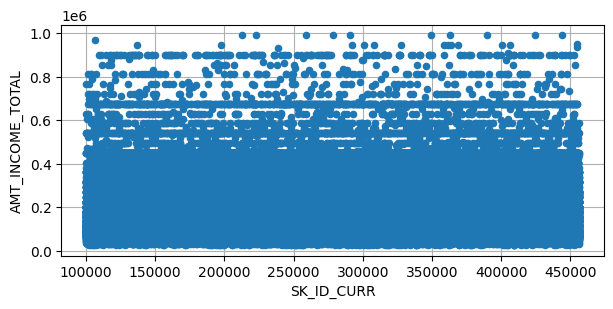

306845

In [31]:
# make a decision here about those 250 people:
# it is true that the amount percentage 0.15% is higher than the count percentage 0.08%
# but those millionaires do not have significantly more loan amount than others
# some might be typo, some might be just regular loans

# might be ok to remove those whose income > 1 mil
# still a majority of records is left with income <= 1mil
# if we need more demographics info about those multi millionaires
# we can run an analysis separately. only 250 records, 1 is probably typo
# let's do the removal
df = remove_outlier(df, 'AMT_INCOME_TOTAL', 1000000)

# check the result
df.boxplot('AMT_INCOME_TOTAL', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='AMT_INCOME_TOTAL', figsize=(7,3), zorder=2, grid=True)
plt.show()

len(df)

In [32]:
# 306845 now compared to 307221 where we started

#### 2. reduce further

In [33]:
# recall
# 1.5 IQR above is: 337500.0
# q99.0 is: 472500.0, count: 3011, percent: 0.98%
# how about we delete those above 500k
# check how many there are first

len(df[df['AMT_INCOME_TOTAL'] > 500000])

2449

In [34]:
# maybe too many
# try 700k

len(df[df['AMT_INCOME_TOTAL'] > 700000])

486

records removed: 486


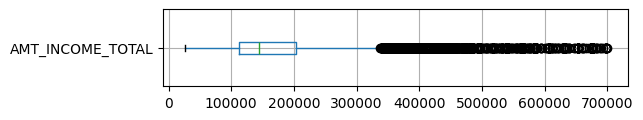

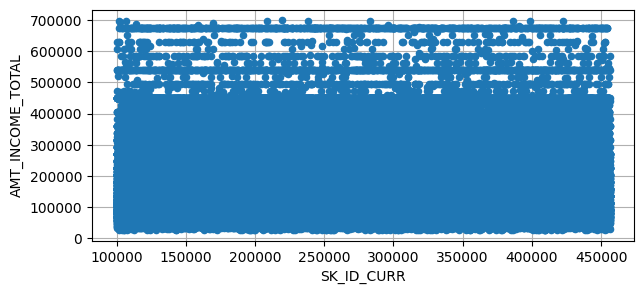

306359

In [35]:
# let's do the removal
df = remove_outlier(df, 'AMT_INCOME_TOTAL', 700000)

# check the result
df.boxplot('AMT_INCOME_TOTAL', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='AMT_INCOME_TOTAL', figsize=(7,3), zorder=2, grid=True)
plt.show()

len(df)

In [36]:
# 306359 now compared to 307221 where we started

### AMT_CREDIT

<Axes: xlabel='SK_ID_CURR', ylabel='AMT_CREDIT'>

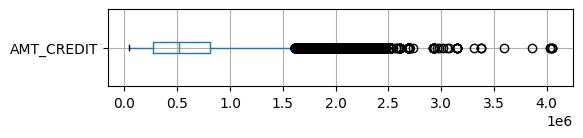

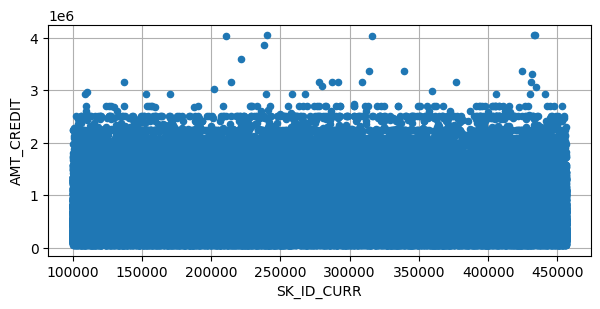

In [37]:
# check credit total
# repeat our process

# 1 chart
df.boxplot(column='AMT_CREDIT', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='AMT_CREDIT', figsize=(7,3), zorder=2, grid=True)

In [38]:
# 2 check outlier
find_outlier(df['AMT_CREDIT'], 0.99)

Report:
1.5 IQR below is: -537975.0, 1.5 IQR above is: 1616625.0
below count: 0, above count: 6396
q99.0 is: 1823242.5, count: 3057, percent: 1.00%
total: 306359


In [39]:
find_outlier(df['AMT_CREDIT'], 0.999)

Report:
1.5 IQR below is: -537975.0, 1.5 IQR above is: 1616625.0
below count: 0, above count: 6396
q99.9 is: 2517300.0, count: 117, percent: 0.04%
total: 306359


records removed: 331


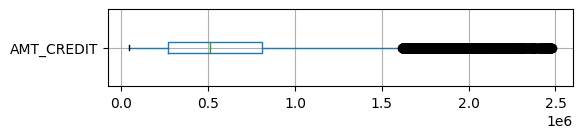

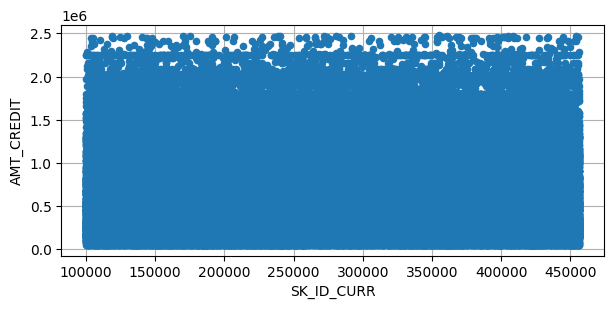

306028

In [40]:
# 3 it is a little arbitrary but let's cut 2.5 * 1e6
# the scatter plot looks much looser above it
df = remove_outlier(df, 'AMT_CREDIT', 2500000)

# check the result
df.boxplot('AMT_CREDIT', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='AMT_CREDIT', figsize=(7,3), zorder=2, grid=True)
plt.show()

len(df)

In [41]:
# 306028 now, (307221)

### AMT_ANNUITY

Report:
1.5 IQR below is: -10579.5, 1.5 IQR above is: 61672.5
below count: 0, above count: 6922
q99.0 is: 69165.0, count: 3056, percent: 1.00%
total: 306028
Report:
1.5 IQR below is: -10579.5, 1.5 IQR above is: 61672.5
below count: 0, above count: 6922
q99.9 is: 106947.0, count: 301, percent: 0.10%
total: 306028


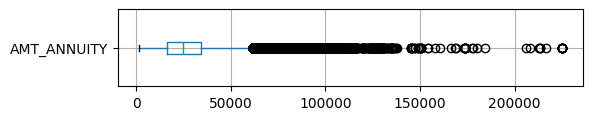

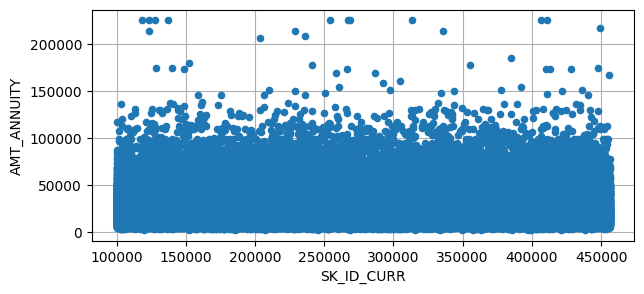

In [42]:
# we can almost copy paste this template as follows:
# 1 chart
df.boxplot(column='AMT_ANNUITY', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='AMT_ANNUITY', figsize=(7,3), zorder=2, grid=True)

# 2 check outlier
find_outlier(df['AMT_ANNUITY'], 0.99)
find_outlier(df['AMT_ANNUITY'], 0.999)

records removed: 121


305907

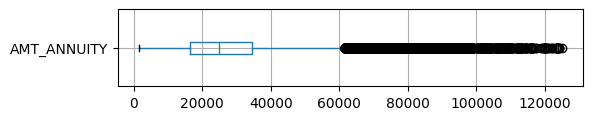

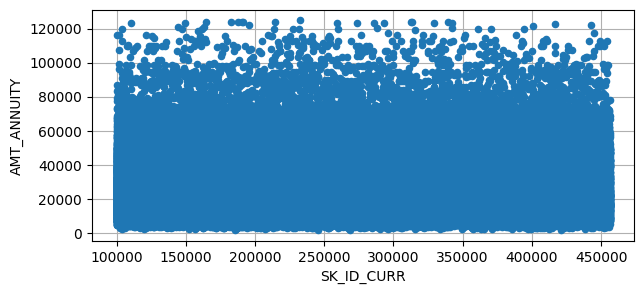

In [43]:
# 3 cut 125000 mostly based on the scatter plot
# there is no common sense number as to
# how much annuity should be
df = remove_outlier(df, 'AMT_ANNUITY', 125000)

# check the result
df.boxplot('AMT_ANNUITY', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='AMT_ANNUITY', figsize=(7,3), zorder=2, grid=True)

len(df)

In [44]:
# 305907 now, (307221)

### AMT_GOODS_PRICE

Report:
1.5 IQR below is: -423000.0, 1.5 IQR above is: 1341000.0
below count: 0, above count: 14022
q99.0 is: 1799730.0000000105, count: 3060, percent: 1.00%
total: 305907
Report:
1.5 IQR below is: -423000.0, 1.5 IQR above is: 1341000.0
below count: 0, above count: 14022
q99.9 is: 2250000.0, count: 47, percent: 0.02%
total: 305907


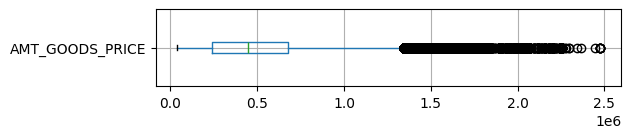

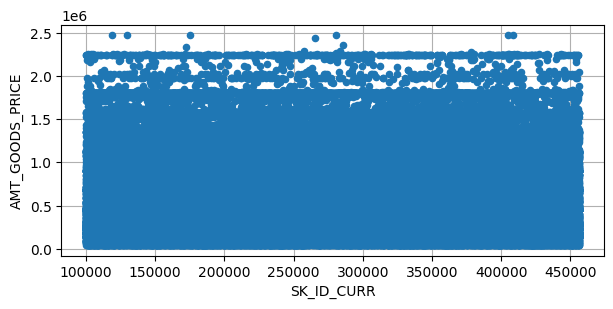

In [45]:
# template:
# 1 chart
df.boxplot(column='AMT_GOODS_PRICE', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='AMT_GOODS_PRICE', figsize=(7,3),
                zorder=2, grid=True)

# 2 check outlier
find_outlier(df['AMT_GOODS_PRICE'], 0.99)
find_outlier(df['AMT_GOODS_PRICE'], 0.999)

records removed: 47


305860

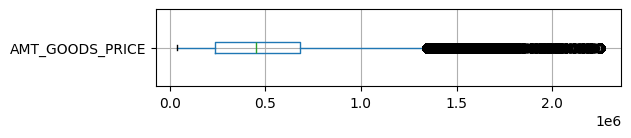

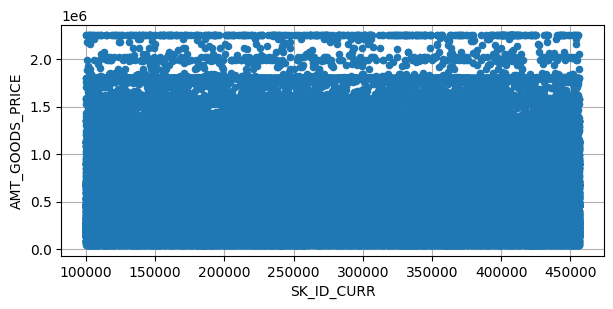

In [46]:
# 3 cut 2250000 or q999
df = remove_outlier(df, 'AMT_GOODS_PRICE', 2250000)

# check the result
df.boxplot('AMT_GOODS_PRICE', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='AMT_GOODS_PRICE', figsize=(7,3), zorder=2, grid=True)

len(df)

In [47]:
# 305860 now, (307221)

### DAYS_BIRTH

#### 1. outlier

Report:
1.5 IQR below is: -30606.0, 1.5 IQR above is: -1494.0
below count: 0, above count: 0
q99.0 is: -8262.0, count: 3053, percent: 1.00%
total: 305860
Report:
1.5 IQR below is: -30606.0, 1.5 IQR above is: -1494.0
below count: 0, above count: 0
q99.9 is: -7759.0, count: 304, percent: 0.10%
total: 305860


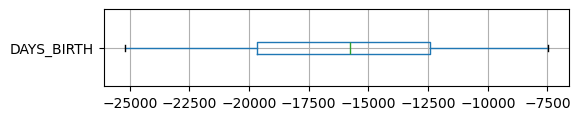

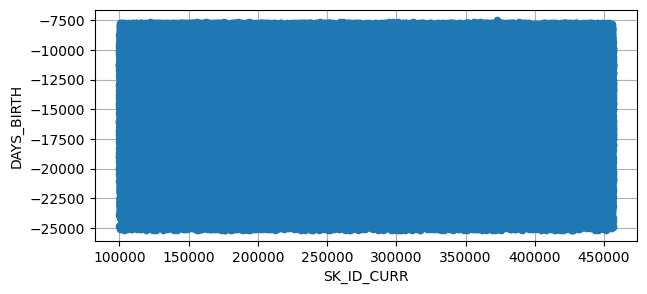

In [48]:
# template:
# 1 chart
df.boxplot(column='DAYS_BIRTH', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='DAYS_BIRTH', figsize=(7,3), zorder=2, grid=True)

# 2 check outlier
find_outlier(df['DAYS_BIRTH'], 0.99)
find_outlier(df['DAYS_BIRTH'], 0.999)

#### 2. convert

In [49]:
# looks ok
# 305860 still
# however days are an awkward unit for age
# let's convert that to years

# loc to replace value, directly use [] will have warning
# since df is a slice of the original df, not copy
df.loc[:, 'DAYS_BIRTH']

0         -9461
1        -16765
2        -19046
3        -19005
4        -19932
          ...  
307506    -9327
307507   -20775
307508   -14966
307509   -11961
307510   -16856
Name: DAYS_BIRTH, Length: 305860, dtype: int64

In [50]:
# to prevent this from being run again, use if
if df['DAYS_BIRTH'].dtype == 'int64':
    df.loc[:, 'DAYS_BIRTH'] = df['DAYS_BIRTH'] / -365
    
df['DAYS_BIRTH']

0         25.920548
1         45.931507
2         52.180822
3         52.068493
4         54.608219
            ...    
307506    25.553425
307507    56.917808
307508    41.002740
307509    32.769863
307510    46.180822
Name: DAYS_BIRTH, Length: 305860, dtype: float64

In [51]:
# change the column name as well
df = df.rename(columns={'DAYS_BIRTH': 'AGE'})
df['AGE']

0         25.920548
1         45.931507
2         52.180822
3         52.068493
4         54.608219
            ...    
307506    25.553425
307507    56.917808
307508    41.002740
307509    32.769863
307510    46.180822
Name: AGE, Length: 305860, dtype: float64

<Axes: >

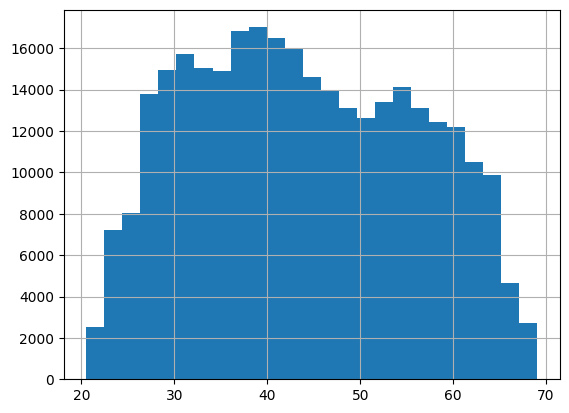

In [52]:
# check hist
df['AGE'].hist(bins=25)

In [53]:
# looks good for 'Age' according to common sense
# 305860 now, (307221)

### DAYS_EMPLOYED

#### 1. outlier

Report:
1.5 IQR below is: -6462.0, 1.5 IQR above is: 3418.0
below count: 16750, above count: 55261
q99.0 is: 365243.0, count: 0, percent: 0.00%
total: 305860
Report:
1.5 IQR below is: -6462.0, 1.5 IQR above is: 3418.0
below count: 16750, above count: 55261
q99.9 is: 365243.0, count: 0, percent: 0.00%
total: 305860


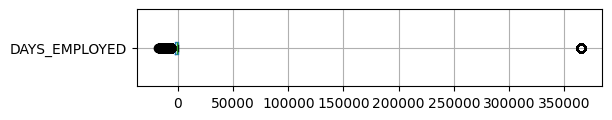

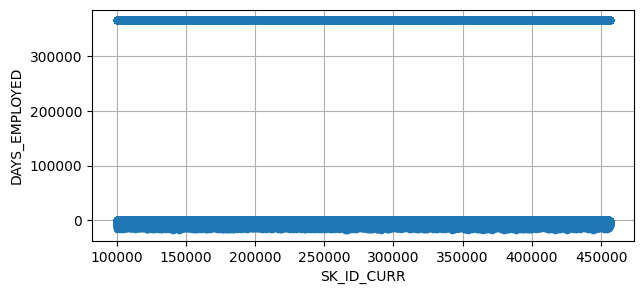

In [54]:
# template:
# 1 chart
df.boxplot(column='DAYS_EMPLOYED', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='DAYS_EMPLOYED', figsize=(7,3), zorder=2, grid=True)

# 2 check outlier
find_outlier(df['DAYS_EMPLOYED'], 0.99)
find_outlier(df['DAYS_EMPLOYED'], 0.999)

In [55]:
# unexpected: every value should be < 0
# change those sky high outliers to value of 1, same int type, but basically an invalid value
# not sure why the original data has this 350000ish value
# which is 1000 years!
# too many records set to this huge number
# guess this means those people are unemployed
df.loc[df['DAYS_EMPLOYED']>200000, 'DAYS_EMPLOYED'] = 1

250599

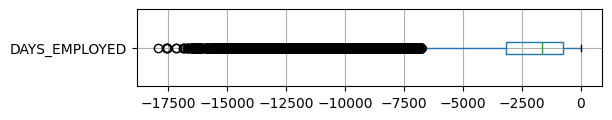

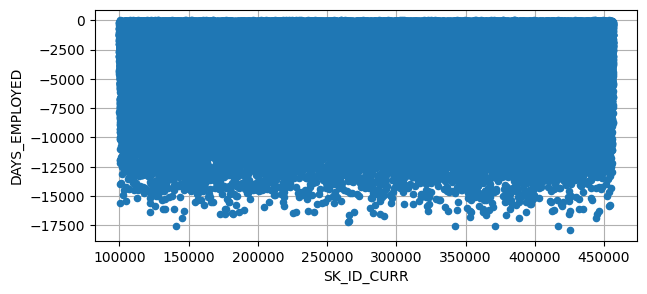

In [56]:
# ignore the ones with value of 1 for a temporary df
df_temp = df[df['DAYS_EMPLOYED'] <= 0]

# check the result
df_temp.boxplot('DAYS_EMPLOYED', figsize=(6,1), vert=False)
df_temp.plot.scatter(x='SK_ID_CURR', y='DAYS_EMPLOYED', figsize=(7,3), zorder=2, grid=True)

len(df_temp)

In [57]:
# looks acceptable
# but we can remove some of the bottoms

In [58]:
# at this point, values become negative
# it is probably wise to revise our functions
# so they can work both ways - negative and positive
# copy the original functions from the 'CNT_CHILDREN' section
# revise as below

# if q < 0.2 it means we are looking at the bottom, not the top
def find_outlier(column, q):
    # regular IQR analysis
    Q1 = column.quantile(0.25)
    Q3 = column.quantile(0.75)
    IQR = Q3 - Q1
    
    below = Q1 - 1.5 * IQR
    above = Q3 + 1.5 * IQR

    below_count = len(column[column < below])
    above_count = len(column[column > above])

    # custom Q analysis
    qresult = column.quantile(q)

    if q > 0.2:
        lentop = len(column[column > qresult])
    else:
        # actually 'lenbottom'
        lentop = len(column[column < qresult])
        
    lentotal = len(column)
    
    percent = lentop / lentotal * 100
    percent_str = f'{percent:.2f}%'

    # report
    print('Report:\n'
          f'1.5 IQR below is: {below}, 1.5 IQR above is: {above}\n'
          f'below count: {below_count}, above count: {above_count}\n'
          f'q{q*100} is: {qresult}, count: {lentop}, percent: {percent_str}\n'
          f'total: {lentotal}')
    
    return None

# check is exclusive of the cutting point
# remove is exclusive
# keep is inclusive
def remove_outlier(df, column, point, top=True):
    if top:
        # remove top
        print(f'records removed: {len(df[df[column] > point])}')
        dfnew = df[df[column] <= point]
    else:
        # remove bottom
        print(f'records removed: {len(df[df[column] < point])}')
        dfnew = df[df[column] >= point]
        
    return dfnew

In [59]:
find_outlier(df['DAYS_EMPLOYED'], 0.001)

Report:
1.5 IQR below is: -6462.0, 1.5 IQR above is: 3418.0
below count: 16750, above count: 0
q0.1 is: -14338.564, count: 306, percent: 0.10%
total: 305860


records removed: 162


305698

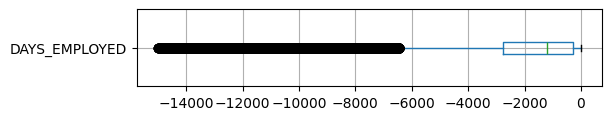

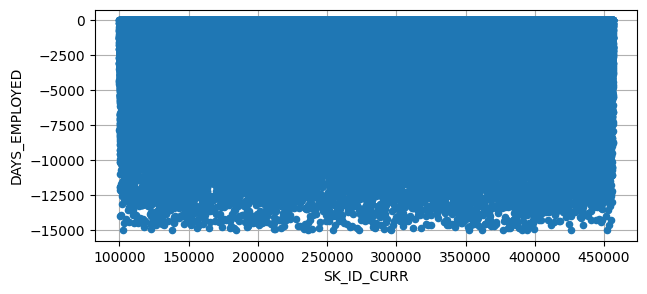

In [60]:
# a little arbitrary but let's remove < 15000 or around q0.1
# which is 41 years, seems long enough to be considered
# 'outlier'

# cut at 15000
df = remove_outlier(df, 'DAYS_EMPLOYED', -15000, top=False)

# check the result
df.boxplot('DAYS_EMPLOYED', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='DAYS_EMPLOYED', figsize=(7,3), zorder=2, grid=True)

len(df)

#### 2. convert

In [61]:
# again, convert to years from days
df['DAYS_EMPLOYED']

0         -637
1        -1188
2         -225
3        -3039
4        -3038
          ... 
307506    -236
307507       1
307508   -7921
307509   -4786
307510   -1262
Name: DAYS_EMPLOYED, Length: 305698, dtype: int64

In [62]:
# to prevent this from being run again, use if
if df['DAYS_EMPLOYED'].dtype == 'int64':
    df.loc[:, 'DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'] / -365
    
df['DAYS_EMPLOYED']

0          1.745205
1          3.254795
2          0.616438
3          8.326027
4          8.323288
            ...    
307506     0.646575
307507    -0.002740
307508    21.701370
307509    13.112329
307510     3.457534
Name: DAYS_EMPLOYED, Length: 305698, dtype: float64

In [63]:
# rename
df = df.rename(columns={'DAYS_EMPLOYED': 'AGE_EMPLOYED'})
df['AGE_EMPLOYED']

0          1.745205
1          3.254795
2          0.616438
3          8.326027
4          8.323288
            ...    
307506     0.646575
307507    -0.002740
307508    21.701370
307509    13.112329
307510     3.457534
Name: AGE_EMPLOYED, Length: 305698, dtype: float64

In [64]:
# the negative values are from those '-1 day'
# means unemployed
# check how many

len(df[df['AGE_EMPLOYED'] < 0])

55261

<Axes: >

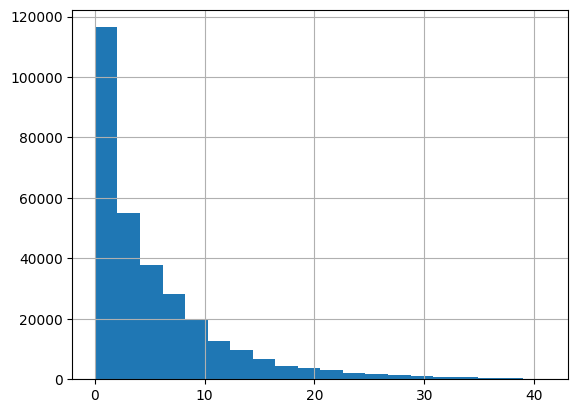

In [65]:
# check hist
df['AGE_EMPLOYED'].hist(bins=20)

In [66]:
# 305698 now, (307221)

### DAYS_REGISTRATION

#### 1. outlier

Report:
1.5 IQR below is: -15684.5, 1.5 IQR above is: 6191.5
below count: 650, above count: 0
q1.0 is: -13878.0, count: 3056, percent: 1.00%
total: 305698
Report:
1.5 IQR below is: -15684.5, 1.5 IQR above is: 6191.5
below count: 650, above count: 0
q0.1 is: -16495.212, count: 306, percent: 0.10%
total: 305698


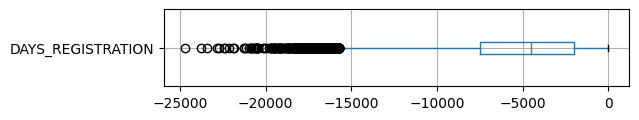

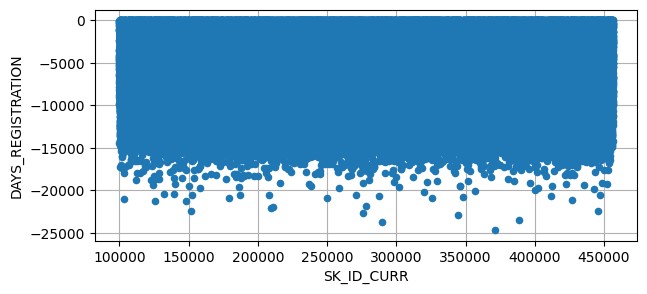

In [67]:
# template:
# 1 chart
df.boxplot(column='DAYS_REGISTRATION', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='DAYS_REGISTRATION', figsize=(7,3), zorder=2, grid=True)

# 2 check outlier
find_outlier(df['DAYS_REGISTRATION'], 0.01)
find_outlier(df['DAYS_REGISTRATION'], 0.001)

records removed: 305


305393

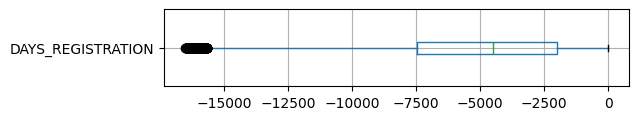

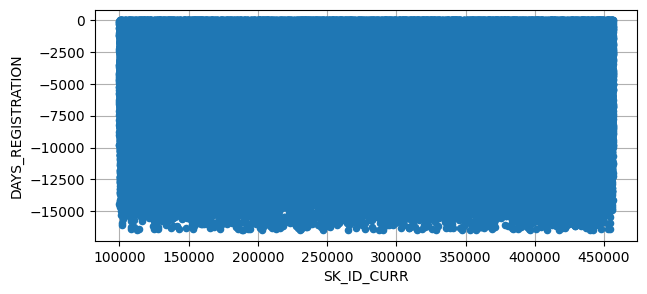

In [68]:
# 3 cut at -16500 or q0.1
# 45 years
df = remove_outlier(df, 'DAYS_REGISTRATION', -16500, top=False)

# check the result
df.boxplot('DAYS_REGISTRATION', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='DAYS_REGISTRATION', figsize=(7,3), zorder=2, grid=True)

len(df)

#### 2. convert

In [69]:
# 1. check
df['DAYS_REGISTRATION']

0        -3648.0
1        -1186.0
2        -4260.0
3        -9833.0
4        -4311.0
           ...  
307506   -8456.0
307507   -4388.0
307508   -6737.0
307509   -2562.0
307510   -5128.0
Name: DAYS_REGISTRATION, Length: 305393, dtype: float64

In [70]:
# 2. convert. it is already float dtype
# so use some other method to detect if it is already converted

if df['DAYS_REGISTRATION'].min() < -1000:
    df.loc[:, 'DAYS_REGISTRATION'] = df['DAYS_REGISTRATION'] / -365

df['DAYS_REGISTRATION']

0          9.994521
1          3.249315
2         11.671233
3         26.939726
4         11.810959
            ...    
307506    23.167123
307507    12.021918
307508    18.457534
307509     7.019178
307510    14.049315
Name: DAYS_REGISTRATION, Length: 305393, dtype: float64

In [71]:
# 3. rename
df = df.rename(columns={'DAYS_REGISTRATION': 'AGE_REGISTRATION'})
df['AGE_REGISTRATION']

0          9.994521
1          3.249315
2         11.671233
3         26.939726
4         11.810959
            ...    
307506    23.167123
307507    12.021918
307508    18.457534
307509     7.019178
307510    14.049315
Name: AGE_REGISTRATION, Length: 305393, dtype: float64

<Axes: >

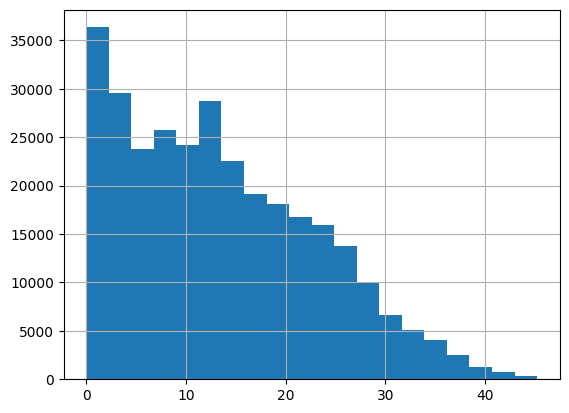

In [72]:
# 4. hist
df['AGE_REGISTRATION'].hist(bins=20)

In [73]:
# looks good
# 305393 now, (307221)

### DAYS_ID_PUBLISH

#### 1. outlier

Report:
1.5 IQR below is: -8166.5, 1.5 IQR above is: 2149.5
below count: 0, above count: 0
q1.0 is: -5446.0, count: 3051, percent: 1.00%
total: 305393
Report:
1.5 IQR below is: -8166.5, 1.5 IQR above is: 2149.5
below count: 0, above count: 0
q0.1 is: -6037.0, count: 305, percent: 0.10%
total: 305393


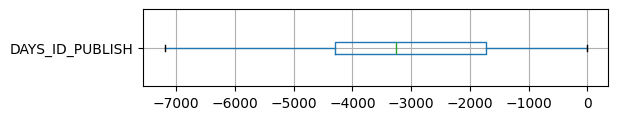

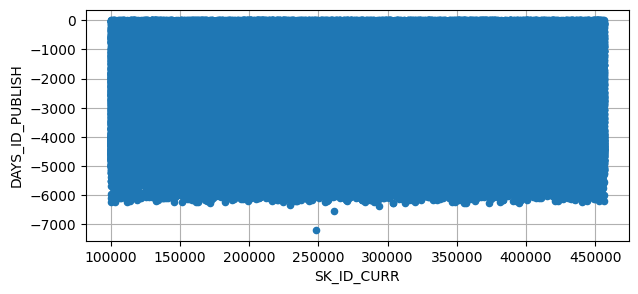

In [74]:
# template:
# 1 chart
df.boxplot(column='DAYS_ID_PUBLISH', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='DAYS_ID_PUBLISH', figsize=(7,3), zorder=2, grid=True)

# 2 check outlier
find_outlier(df['DAYS_ID_PUBLISH'], 0.01)
find_outlier(df['DAYS_ID_PUBLISH'], 0.001)

In [75]:
find_outlier(df['DAYS_ID_PUBLISH'], 0.0001)

Report:
1.5 IQR below is: -8166.5, 1.5 IQR above is: 2149.5
below count: 0, above count: 0
q0.01 is: -6211.4608, count: 31, percent: 0.01%
total: 305393


records removed: 31


305362

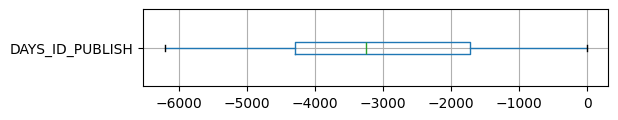

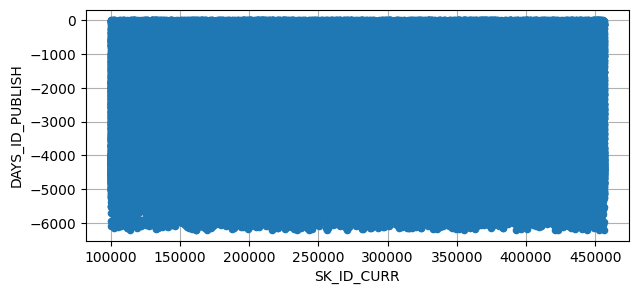

In [76]:
# cut at -6211
df = remove_outlier(df, 'DAYS_ID_PUBLISH', -6211, top=False)

# check the result
df.boxplot('DAYS_ID_PUBLISH', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='DAYS_ID_PUBLISH', figsize=(7,3), zorder=2, grid=True)

len(df)

#### 2. convert

In [77]:
# rinse and repeat
# 1. check
df['DAYS_ID_PUBLISH']

0        -2120
1         -291
2        -2531
3        -2437
4        -3458
          ... 
307506   -1982
307507   -4090
307508   -5150
307509    -931
307510    -410
Name: DAYS_ID_PUBLISH, Length: 305362, dtype: int64

In [78]:
# 2. convert

if df['DAYS_ID_PUBLISH'].dtype == 'int64':
    df.loc[:, 'DAYS_ID_PUBLISH'] = df['DAYS_ID_PUBLISH'] / -365

df['DAYS_ID_PUBLISH']

0          5.808219
1          0.797260
2          6.934247
3          6.676712
4          9.473973
            ...    
307506     5.430137
307507    11.205479
307508    14.109589
307509     2.550685
307510     1.123288
Name: DAYS_ID_PUBLISH, Length: 305362, dtype: float64

In [79]:
# 3. rename
df = df.rename(columns={'DAYS_ID_PUBLISH': 'AGE_ID'})
df['AGE_ID']

0          5.808219
1          0.797260
2          6.934247
3          6.676712
4          9.473973
            ...    
307506     5.430137
307507    11.205479
307508    14.109589
307509     2.550685
307510     1.123288
Name: AGE_ID, Length: 305362, dtype: float64

<Axes: >

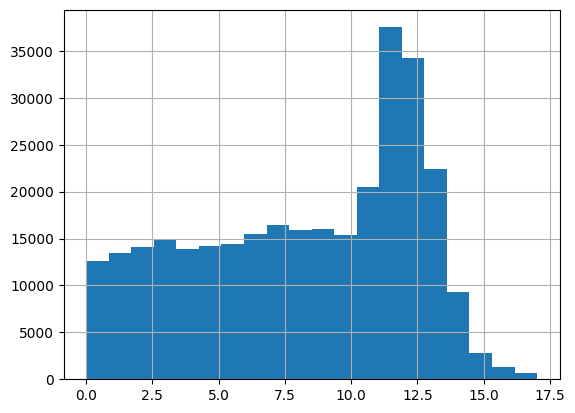

In [80]:
# 4. hist
df['AGE_ID'].hist(bins=20)

In [81]:
# these 'age' columns can be useful in later logistic regression
# 305362 now, (307221)

### OWN_CAR_AGE

#### 1. outlier

Report:
1.5 IQR below is: -10.0, 1.5 IQR above is: 30.0
below count: 0, above count: 4920
q99.0 is: 64.0, count: 892, percent: 0.86%
total: 103691


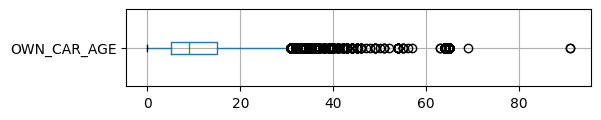

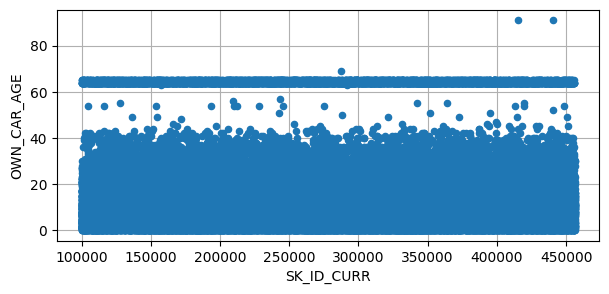

In [82]:
# recall we set NaN to -1 in this column
# there are a lot of records with -1
# take that out temporarily for q analysis

# template:
# 1 chart
df_car = df[df['OWN_CAR_AGE'] >= 0]
df_car.boxplot(column='OWN_CAR_AGE', figsize=(6,1), vert=False)
df_car.plot.scatter(x='SK_ID_CURR', y='OWN_CAR_AGE', figsize=(7,3), zorder=2, grid=True)

# 2 check outlier
find_outlier(df_car['OWN_CAR_AGE'], 0.99)

In [83]:
# the bunch of records just above 60 seems weird
# do some investigation
for i in range(60,70):
    print(i, len(df[df['OWN_CAR_AGE']==i]))

60 0
61 0
62 0
63 2
64 2436
65 889
66 0
67 0
68 0
69 1


records removed: 3366


301996

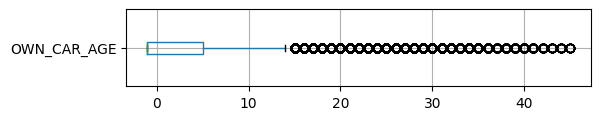

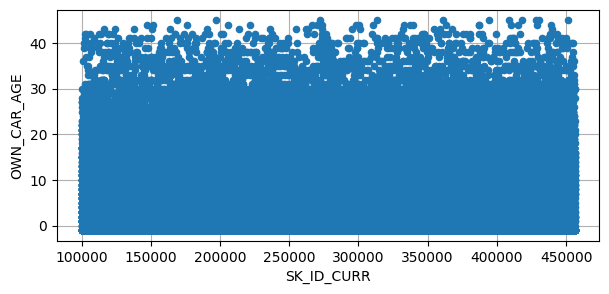

In [84]:
# is it a coincidence that there are so many 64 years old cars?
# not sure. but guess we have to cut them
# not a common thing to see 60+ yrs old cars running around
# consider 1.5 IQR above is 30 and look at the scatter plot
# cut 45 should be ok

df = remove_outlier(df, 'OWN_CAR_AGE', 45, top=True)

# check the result
df.boxplot('OWN_CAR_AGE', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='OWN_CAR_AGE', figsize=(7,3), zorder=2, grid=True)

len(df)

#### 2. convert

In [85]:
# just rename to be consistent with other age columns
df = df.rename(columns={'OWN_CAR_AGE': 'AGE_CAR'})
df['AGE_CAR']

0         -1.0
1         -1.0
2         26.0
3         -1.0
4         -1.0
          ... 
307506    -1.0
307507    -1.0
307508    -1.0
307509    -1.0
307510    -1.0
Name: AGE_CAR, Length: 301996, dtype: float64

<Axes: >

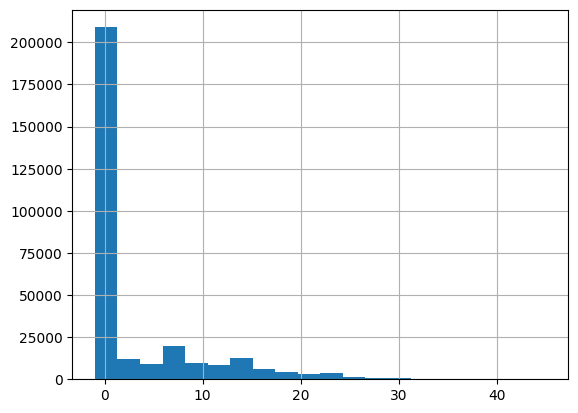

In [86]:
df['AGE_CAR'].hist(bins=20)

#### 3. misc

In [87]:
# one tiny thing is there are some discrepancy
# between CAR_AGE == -1 and FLAG_OWN_CAR == 'N'

df[(df['AGE_CAR'] == -1) & (df['FLAG_OWN_CAR'] == 'Y')][['AGE_CAR', 'FLAG_OWN_CAR']]

,AGE_CAR,FLAG_OWN_CAR
30897,-1.0,Y
181231,-1.0,Y
217549,-1.0,Y
229867,-1.0,Y
236868,-1.0,Y


In [88]:
# drop them
df = df[~( (df['AGE_CAR'] == -1) & (df['FLAG_OWN_CAR'] == 'Y') ) ]
df

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,TARGET
0,100002,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,...,Laborers,1.0,0,0,0,0,0,0,Business Entity Type 3,1
1,100003,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,...,Core staff,2.0,0,0,0,0,0,0,School,0
2,100004,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,...,Laborers,1.0,0,0,0,0,0,0,Government,0
3,100006,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,...,Laborers,2.0,0,0,0,0,0,0,Business Entity Type 3,0
4,100007,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,...,Core staff,1.0,0,0,0,0,1,1,Religion,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,225000.0,...,Sales staff,1.0,0,0,0,0,0,0,Services,0
307507,456252,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,225000.0,...,Unknown,1.0,0,0,0,0,0,0,XNA,0
307508,456253,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,585000.0,...,Managers,1.0,0,0,0,0,1,1,School,0
307509,456254,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,319500.0,...,Laborers,2.0,0,0,0,1,1,0,Business Entity Type 1,1


In [89]:
# 301991 now, (307221)

### OCCUPATION_TYPE 

In [90]:
# since it's str type, we cannot use the template from above
df['OCCUPATION_TYPE'].value_counts()

OCCUPATION_TYPE
Unknown                  95059
Laborers                 54231
Sales staff              31577
Core staff               27045
Managers                 20538
Drivers                  18320
High skill tech staff    11128
Accountants               9603
Medicine staff            8374
Security staff            6610
Cooking staff             5860
Cleaning staff            4591
Private service staff     2594
Low-skill Laborers        2054
Waiters/barmen staff      1325
Secretaries               1282
Realty agents              740
HR staff                   553
IT staff                   507
Name: count, dtype: int64

In [91]:
# seems ok, did not change so still the same len of df
# 301991 now, (307221)

### CNT_FAM_MEMBERS

Report:
1.5 IQR below is: 0.5, 1.5 IQR above is: 4.5
below count: 0, above count: 3804
q99.0 is: 5.0, count: 397, percent: 0.13%
total: 301991
Report:
1.5 IQR below is: 0.5, 1.5 IQR above is: 4.5
below count: 0, above count: 3804
q99.9 is: 6.0, count: 0, percent: 0.00%
total: 301991


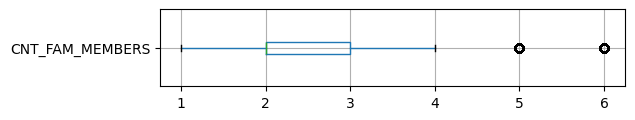

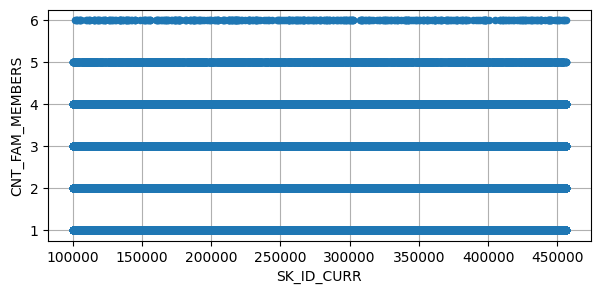

In [92]:
# template:
# 1 chart
df.boxplot(column='CNT_FAM_MEMBERS', figsize=(6,1), vert=False)
df.plot.scatter(x='SK_ID_CURR', y='CNT_FAM_MEMBERS', figsize=(7,3), zorder=2, grid=True)

# 2 check outlier
find_outlier(df['CNT_FAM_MEMBERS'], 0.99)
find_outlier(df['CNT_FAM_MEMBERS'], 0.999)

In [93]:
# should be ok to leave as is
# if we adopted the 1.5 IQR method then 3804 records will be removed
# may be too many
# still 301991 now, (307221)

### ORGANIZATION_TYPE

In [94]:
# it's str type again
df['ORGANIZATION_TYPE'].value_counts()

ORGANIZATION_TYPE
Business Entity Type 3    66504
XNA                       54830
Self-employed             37785
Other                     16354
Medicine                  10963
Business Entity Type 2    10290
Government                10227
School                     8748
Trade: type 7              7689
Kindergarten               6795
Construction               6597
Business Entity Type 1     5845
Transport: type 4          5300
Trade: type 3              3435
Industry: type 9           3304
Industry: type 3           3222
Security                   3185
Housing                    2910
Industry: type 11          2648
Military                   2570
Bank                       2438
Agriculture                2412
Police                     2286
Transport: type 2          2165
Postal                     2127
Security Ministries        1925
Trade: type 2              1854
Restaurant                 1770
Services                   1540
University                 1293
Industry: type 7      

In [95]:
# seems ok
# 301991 now, (307221)

### Others

In [96]:
# check the str type and binary type columns to see if there are abnormalies
check_list = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE',
             'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE',
             'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL',
             'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
             'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'TARGET']

for i in check_list:
    print(df[i].value_counts(), '\n')

NAME_CONTRACT_TYPE
Cash loans         273803
Revolving loans     28188
Name: count, dtype: int64 

CODE_GENDER
F      199104
M      102883
XNA         4
Name: count, dtype: int64 

FLAG_OWN_CAR
N    201666
Y    100325
Name: count, dtype: int64 

FLAG_OWN_REALTY
Y    209408
N     92583
Name: count, dtype: int64 

NAME_TYPE_SUITE
Unaccompanied      244213
Family              39505
Spouse, partner     11219
Children             3222
Other_B              1738
Unknown               985
Other_A               845
Group of people       264
Name: count, dtype: int64 

NAME_INCOME_TYPE
Working                 155883
Commercial associate     69939
Pensioner                54818
State servant            21301
Unemployed                  21
Student                     18
Businessman                  6
Maternity leave              5
Name: count, dtype: int64 

NAME_EDUCATION_TYPE
Secondary / secondary special    215474
Higher education                  72538
Incomplete higher                 10049
L

In [97]:
# seems ok

### Export to csv

In [98]:
# cleaning and outlier removal are complete
# check the df now
df

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,TARGET
0,100002,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,...,Laborers,1.0,0,0,0,0,0,0,Business Entity Type 3,1
1,100003,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,...,Core staff,2.0,0,0,0,0,0,0,School,0
2,100004,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,...,Laborers,1.0,0,0,0,0,0,0,Government,0
3,100006,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,...,Laborers,2.0,0,0,0,0,0,0,Business Entity Type 3,0
4,100007,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,...,Core staff,1.0,0,0,0,0,1,1,Religion,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,225000.0,...,Sales staff,1.0,0,0,0,0,0,0,Services,0
307507,456252,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,225000.0,...,Unknown,1.0,0,0,0,0,0,0,XNA,0
307508,456253,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,585000.0,...,Managers,1.0,0,0,0,0,1,1,School,0
307509,456254,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,319500.0,...,Laborers,2.0,0,0,0,1,1,0,Business Entity Type 1,1


In [99]:
df.describe()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,AGE,AGE_EMPLOYED,AGE_REGISTRATION,AGE_ID,...,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,TARGET
count,301991.000000,301991.000000,301991.000000,3.019910e+05,301991.000000,3.019910e+05,301991.000000,301991.000000,301991.000000,301991.000000,...,301991.000000,301991.000000,301991.000000,301991.000000,301991.000000,301991.000000,301991.000000,301991.000000,301991.000000,301991.000000
mean,278159.322635,0.413496,165820.171490,5.954274e+05,26952.516194,5.347469e+05,43.978512,5.328994,13.642320,8.207691,...,0.281432,0.056336,2.149978,0.015027,0.050376,0.040299,0.078208,0.230408,0.179558,0.080933
std,102793.025755,0.710710,85299.541881,3.940471e+05,13997.221054,3.613969e+05,11.949272,6.265308,9.596039,4.132144,...,0.449699,0.230570,0.900918,0.121660,0.218719,0.196660,0.268498,0.421094,0.383820,0.272732
min,100002.000000,0.000000,25650.000000,4.500000e+04,1615.500000,4.050000e+04,21.021918,-0.002740,-0.000000,-0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189120.500000,0.000000,112500.000000,2.700000e+05,16524.000000,2.385000e+05,34.057534,0.778082,5.515068,4.720548,...,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278193.000000,0.000000,144000.000000,5.124465e+05,24867.000000,4.500000e+05,43.205479,3.312329,12.345205,8.923288,...,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,367121.500000,1.000000,202500.000000,8.086500e+05,34573.500000,6.795000e+05,53.967123,7.550685,20.484932,11.778082,...,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,456255.000000,4.000000,699750.000000,2.479860e+06,124893.000000,2.250000e+06,69.043836,41.071233,45.200000,17.016438,...,1.000000,1.000000,6.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [100]:
df.isna().sum()

SK_ID_CURR                     0
NAME_CONTRACT_TYPE             0
CODE_GENDER                    0
FLAG_OWN_CAR                   0
FLAG_OWN_REALTY                0
CNT_CHILDREN                   0
AMT_INCOME_TOTAL               0
AMT_CREDIT                     0
AMT_ANNUITY                    0
AMT_GOODS_PRICE                0
NAME_TYPE_SUITE                0
NAME_INCOME_TYPE               0
NAME_EDUCATION_TYPE            0
NAME_FAMILY_STATUS             0
NAME_HOUSING_TYPE              0
AGE                            0
AGE_EMPLOYED                   0
AGE_REGISTRATION               0
AGE_ID                         0
AGE_CAR                        0
FLAG_MOBIL                     0
FLAG_EMP_PHONE                 0
FLAG_WORK_PHONE                0
FLAG_CONT_MOBILE               0
FLAG_PHONE                     0
FLAG_EMAIL                     0
OCCUPATION_TYPE                0
CNT_FAM_MEMBERS                0
REG_REGION_NOT_LIVE_REGION     0
REG_REGION_NOT_WORK_REGION     0
LIVE_REGIO

In [101]:
df.nunique()

SK_ID_CURR                     301991
NAME_CONTRACT_TYPE                  2
CODE_GENDER                         3
FLAG_OWN_CAR                        2
FLAG_OWN_REALTY                     2
CNT_CHILDREN                        5
AMT_INCOME_TOTAL                 2395
AMT_CREDIT                       5511
AMT_ANNUITY                     13469
AMT_GOODS_PRICE                   977
NAME_TYPE_SUITE                     8
NAME_INCOME_TYPE                    8
NAME_EDUCATION_TYPE                 5
NAME_FAMILY_STATUS                  5
NAME_HOUSING_TYPE                   6
AGE                             17453
AGE_EMPLOYED                    12386
AGE_REGISTRATION                15383
AGE_ID                           6139
AGE_CAR                            47
FLAG_MOBIL                          2
FLAG_EMP_PHONE                      2
FLAG_WORK_PHONE                     2
FLAG_CONT_MOBILE                    2
FLAG_PHONE                          2
FLAG_EMAIL                          2
OCCUPATION_T

In [102]:
# might be useful to save all the work up to this point to a new csv
# we will read the new csv from later sections

# only need to run this export once
# since we may need to re-run the codes when re-opening the notebook
# set some safeguard

import os

if not os.path.exists('application_train_clean.csv'):
    df.to_csv('application_train_clean.csv', index=False)

## 4. Analysis

### Reload the df

In [103]:
# add ',' for thousands and round to 0.1
pd.options.display.float_format = '{:,.1f}'.format
df = pd.read_csv('application_train_clean.csv')

df.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,TARGET
0,100002,Cash loans,M,N,Y,0,"202,500.0","406,597.5","24,700.5","351,000.0",...,Laborers,1.0,0,0,0,0,0,0,Business Entity Type 3,1
1,100003,Cash loans,F,N,N,0,"270,000.0","1,293,502.5","35,698.5","1,129,500.0",...,Core staff,2.0,0,0,0,0,0,0,School,0
2,100004,Revolving loans,M,Y,Y,0,"67,500.0","135,000.0","6,750.0","135,000.0",...,Laborers,1.0,0,0,0,0,0,0,Government,0
3,100006,Cash loans,F,N,Y,0,"135,000.0","312,682.5","29,686.5","297,000.0",...,Laborers,2.0,0,0,0,0,0,0,Business Entity Type 3,0
4,100007,Cash loans,M,N,Y,0,"121,500.0","513,000.0","21,865.5","513,000.0",...,Core staff,1.0,0,0,0,0,1,1,Religion,0


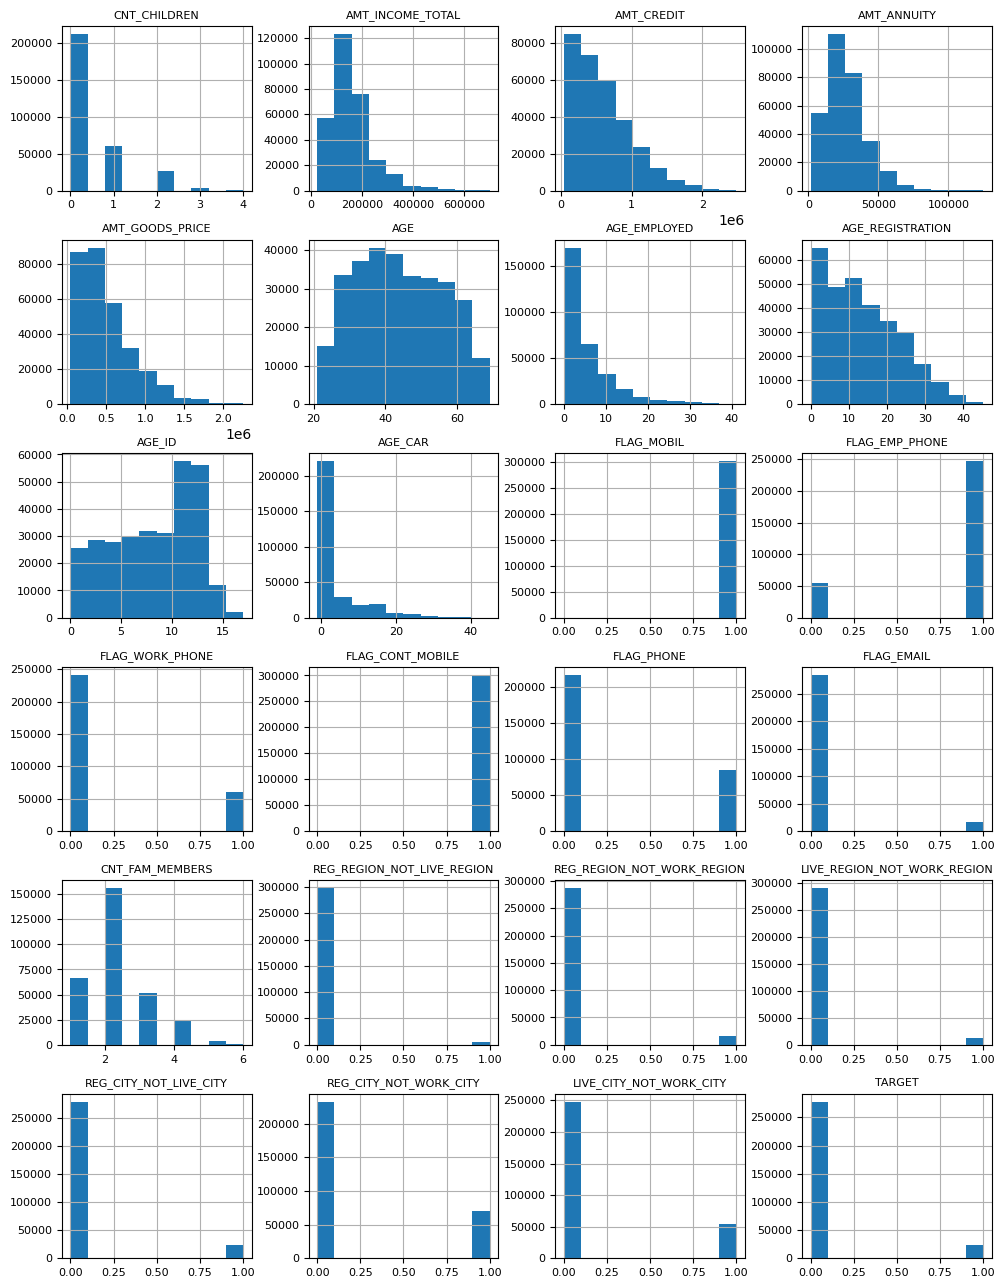

In [104]:
fig = df.loc[:, 'CNT_CHILDREN':].hist(layout=(6,4), figsize=(12,16))
for x in fig:
    for j in x:
        j.title.set_size(8)
        j.tick_params(axis='both', labelsize=8)

### General analysis

In [105]:
# How much (total) do they have out in loans?
loan_sum = df['AMT_CREDIT'].sum()
f'${loan_sum:,}'

'$179,813,705,827.5'

In [106]:
# How much are in default/late?
# Target variable: 1 - client with payment difficulties
target_count = df.groupby('TARGET', as_index=False)['SK_ID_CURR'].count()

# How much are in default/late?
target_amt = df.groupby('TARGET', as_index=False)['AMT_CREDIT'].sum()

target_count, target_amt

(   TARGET  SK_ID_CURR
 0       0      277550
 1       1       24441,
    TARGET        AMT_CREDIT
 0       0 166,218,071,859.0
 1       1  13,595,633,968.5)

In [107]:
# What percentage of the business are default and late?
# percent_count = target_count[1] / (target_count[0] + target_count[1]) * 100
percent_count = (target_count['SK_ID_CURR'][1] /
                (target_count['SK_ID_CURR'][0] + target_count['SK_ID_CURR'][1]) * 100)
f'{percent_count:.2f} % is in trouble by count'

'8.09 % is in trouble by count'

In [108]:
# What percentage of the business are default and late?
percent_amt = (target_amt['AMT_CREDIT'][1] /
                (target_amt['AMT_CREDIT'][0] + target_amt['AMT_CREDIT'][1]) * 100)
f'{percent_amt:.2f} % is in trouble by amount'

'7.56 % is in trouble by amount'

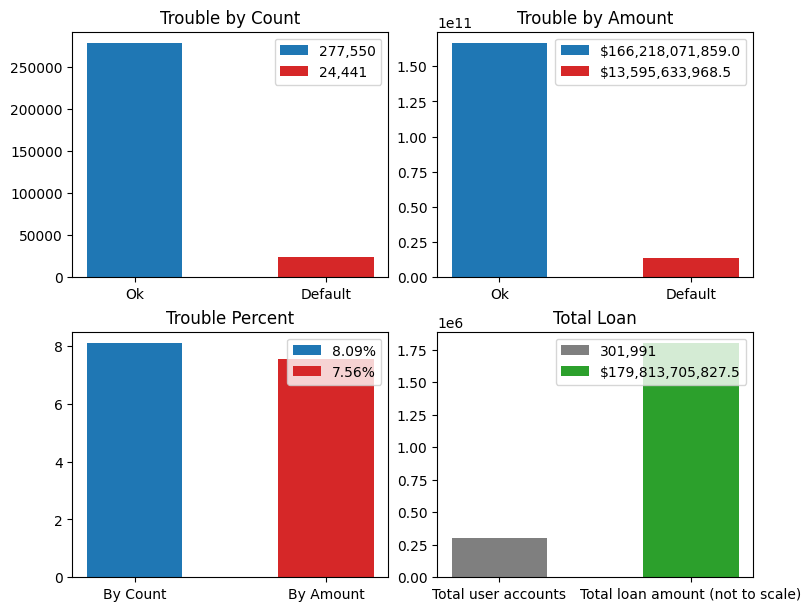

In [109]:
# putting it altogether so we have a graphic report
fig, axs = plt.subplots(2, 2, figsize=(8,6), layout='constrained')

axs[0, 0].bar(target_count['TARGET'], target_count['SK_ID_CURR'],
              label=[f'{target_count["SK_ID_CURR"][0]:,}', f'{target_count["SK_ID_CURR"][1]:,}'],
              width=0.5, color=['tab:blue', 'tab:red'])
axs[0, 0].set_title('Trouble by Count')
axs[0, 0].set_xticks(target_count['TARGET'], labels=['Ok', 'Default'])

axs[0, 1].bar(target_amt['TARGET'], target_amt['AMT_CREDIT'],
              label=[f'${target_amt["AMT_CREDIT"][0]:,}', f'${target_amt["AMT_CREDIT"][1]:,}'],
              width=0.5, color=['tab:blue', 'tab:red'])
axs[0, 1].set_title('Trouble by Amount')
axs[0, 1].set_xticks(target_amt['TARGET'], labels=['Ok', 'Default'])

axs[1, 0].bar([0,1], [percent_count, percent_amt],
              label=[f'{percent_count:.2f}%', f'{percent_amt:.2f}%'],
              width=0.5, color=['tab:blue', 'tab:red'])
axs[1, 0].set_title('Trouble Percent')
axs[1, 0].set_xticks([0,1], labels=['By Count', 'By Amount'])

axs[1, 1].bar([0,1], [len(df), loan_sum/100000],
              label=[f'{len(df):,}', f'${loan_sum:,}'],
              width=0.5, color=['tab:grey', 'tab:green'])
axs[1, 1].set_title('Total Loan')
axs[1, 1].set_xticks([0,1], labels=['Total user accounts',
                                    'Total loan amount (not to scale)'])

# show legends
for i in axs:
    for j in i:
        j.legend(loc=1)

### Demographic analysis

####  1. Pie

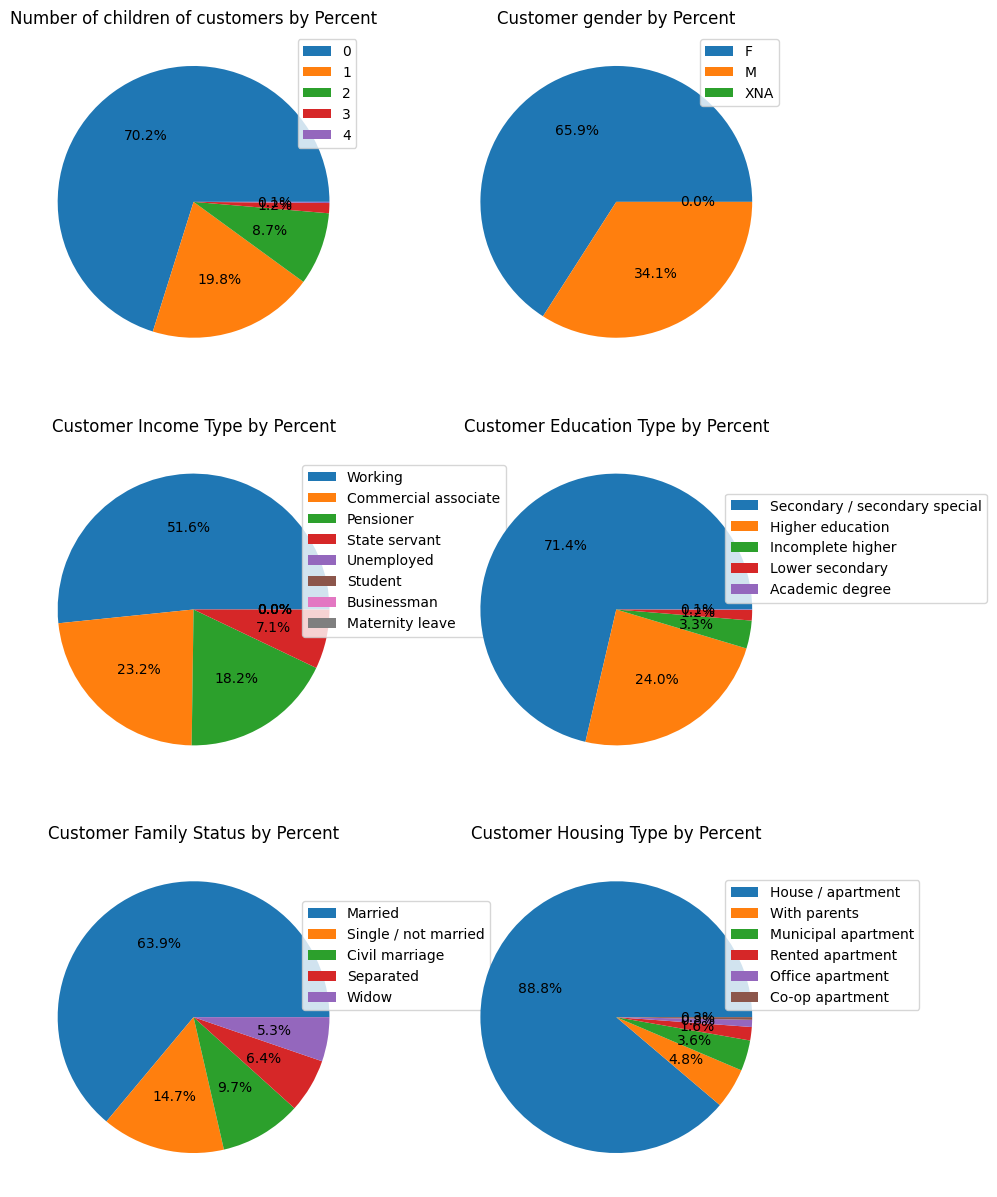

In [110]:
# demographics of the customers
# age, education, income, marital status
# employment, family structure, gender, occupation etc

sr_children = df['CNT_CHILDREN'].value_counts()
sr_gender = df['CODE_GENDER'].value_counts()
sr_income_type = df['NAME_INCOME_TYPE'].value_counts()
sr_education_type = df['NAME_EDUCATION_TYPE'].value_counts()
sr_family = df['NAME_FAMILY_STATUS'].value_counts()
sr_housing = df['NAME_HOUSING_TYPE'].value_counts()

# the pie report
fig, axs = plt.subplots(3, 2, figsize=(10,15))

axs[0,0].pie(sr_children, labels=sr_children.index.values, labeldistance=None, autopct='%1.1f%%', radius=1)
axs[0,0].set_title('Number of children of customers by Percent')
axs[0,0].legend()

axs[0,1].pie(sr_gender, labels=sr_gender.index.values, labeldistance=None, autopct='%1.1f%%')
axs[0,1].set_title('Customer gender by Percent')
axs[0,1].legend()

axs[1,0].pie(sr_income_type, labels=sr_income_type.index.values, labeldistance=None, autopct='%1.1f%%')
axs[1,0].set_title('Customer Income Type by Percent')
axs[1,0].legend(loc='lower left', bbox_to_anchor=(0.8, 0.4, 0.1, 0.1))

axs[1,1].pie(sr_education_type, labels=sr_education_type.index.values, labeldistance=None, autopct='%1.1f%%')
axs[1,1].set_title('Customer Education Type by Percent')
axs[1,1].legend(loc='lower left', bbox_to_anchor=(0.8, 0.5, 0.1, 0.1))

axs[2,0].pie(sr_family, labels=sr_family.index.values, labeldistance=None, autopct='%1.1f%%')
axs[2,0].set_title('Customer Family Status by Percent')
axs[2,0].legend(loc='lower left', bbox_to_anchor=(0.8, 0.5, 0.1, 0.1))

axs[2,1].pie(sr_housing, labels=sr_housing.index.values, labeldistance=None, autopct='%1.1f%%')
axs[2,1].set_title('Customer Housing Type by Percent')
axs[2,1].legend(loc='lower left', bbox_to_anchor=(0.8, 0.5, 0.1, 0.1))

#### 2. Histogram

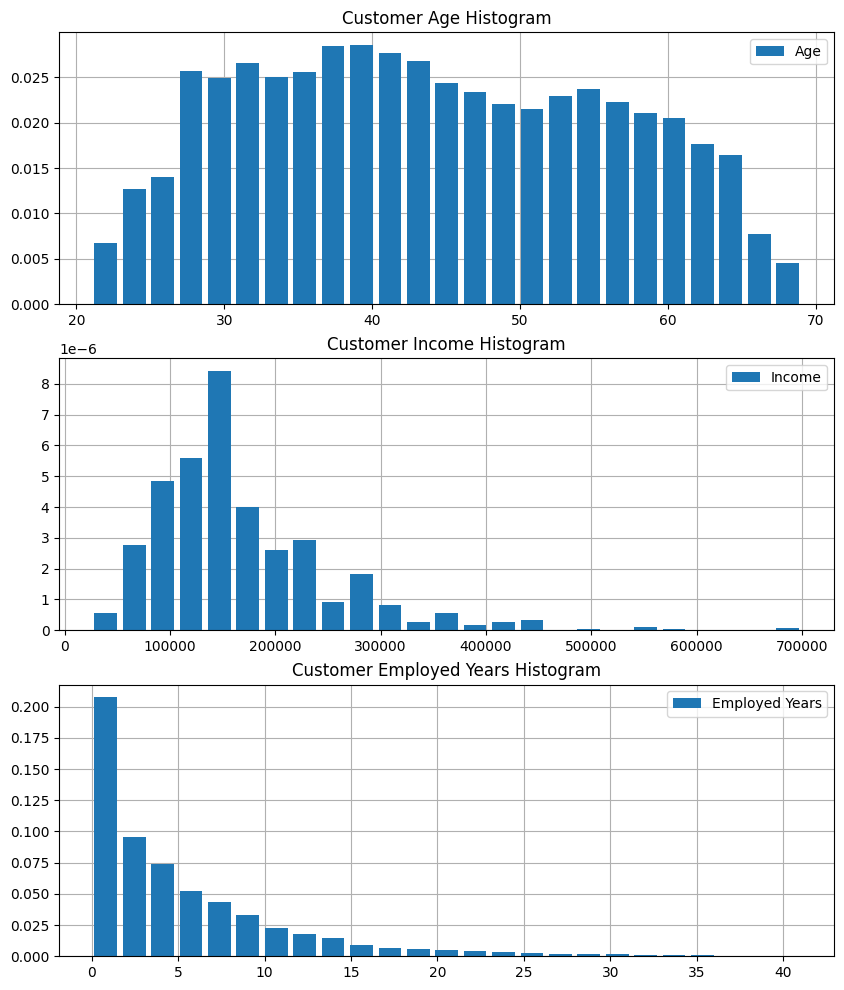

In [111]:
sr_age = df['AGE']
sr_employed = df['AGE_EMPLOYED']
sr_income = df['AMT_INCOME_TOTAL']

# hist report
fig1, axs1 = plt.subplots(3, 1, figsize=(10,12))

# sr_age.plot.hist(ax=axs1[0], bins=25, rwidth=0.8, density=True)
axs1[0].hist(sr_age, bins=25, rwidth=0.8, density=True, zorder=2)
axs1[0].grid(True)
axs1[0].set_title('Customer Age Histogram')
axs1[0].legend(labels=['Age'])

axs1[1].hist(sr_income, bins=25, rwidth=0.8, density=True, zorder=2)
axs1[1].grid(True)
axs1[1].set_title('Customer Income Histogram')
axs1[1].legend(labels=['Income'])

axs1[2].hist(sr_employed, bins=25, rwidth=0.8, density=True, zorder=2)
axs1[2].grid(True)
axs1[2].set_title('Customer Employed Years Histogram')
axs1[2].legend(labels=['Employed Years'])

#### 3. Bin

In [112]:
df['AGEBIN'] = pd.cut(df['AGE'], bins=[20, 30, 40, 50, 60, 80],
                     labels=['20-30','30-40','40-50','50-60','60+'])

df_edu_age_income = df.groupby(['NAME_EDUCATION_TYPE', 'AGEBIN'], as_index=False, observed=True)['AMT_INCOME_TOTAL'].mean()
df_edu_age_income

,NAME_EDUCATION_TYPE,AGEBIN,AMT_INCOME_TOTAL
0,Academic degree,20-30,"201,000.0"
1,Academic degree,30-40,"248,062.5"
2,Academic degree,40-50,"245,736.7"
3,Academic degree,50-60,"208,950.0"
4,Academic degree,60+,"160,464.7"
5,Higher education,20-30,"178,944.1"
6,Higher education,30-40,"205,996.8"
7,Higher education,40-50,"217,725.2"
8,Higher education,50-60,"209,060.8"
9,Higher education,60+,"173,822.5"


In [113]:
df_fam_age_income = df.groupby(['NAME_FAMILY_STATUS', 'AGEBIN'], as_index=False, observed=True)['AMT_INCOME_TOTAL'].mean()
df_fam_age_income

,NAME_FAMILY_STATUS,AGEBIN,AMT_INCOME_TOTAL
0,Civil marriage,20-30,"156,753.2"
1,Civil marriage,30-40,"167,490.7"
2,Civil marriage,40-50,"175,424.0"
3,Civil marriage,50-60,"164,290.0"
4,Civil marriage,60+,"144,260.0"
5,Married,20-30,"157,438.9"
6,Married,30-40,"175,076.9"
7,Married,40-50,"177,680.6"
8,Married,50-60,"163,888.9"
9,Married,60+,"139,521.4"


Text(0, 0.5, 'Income')

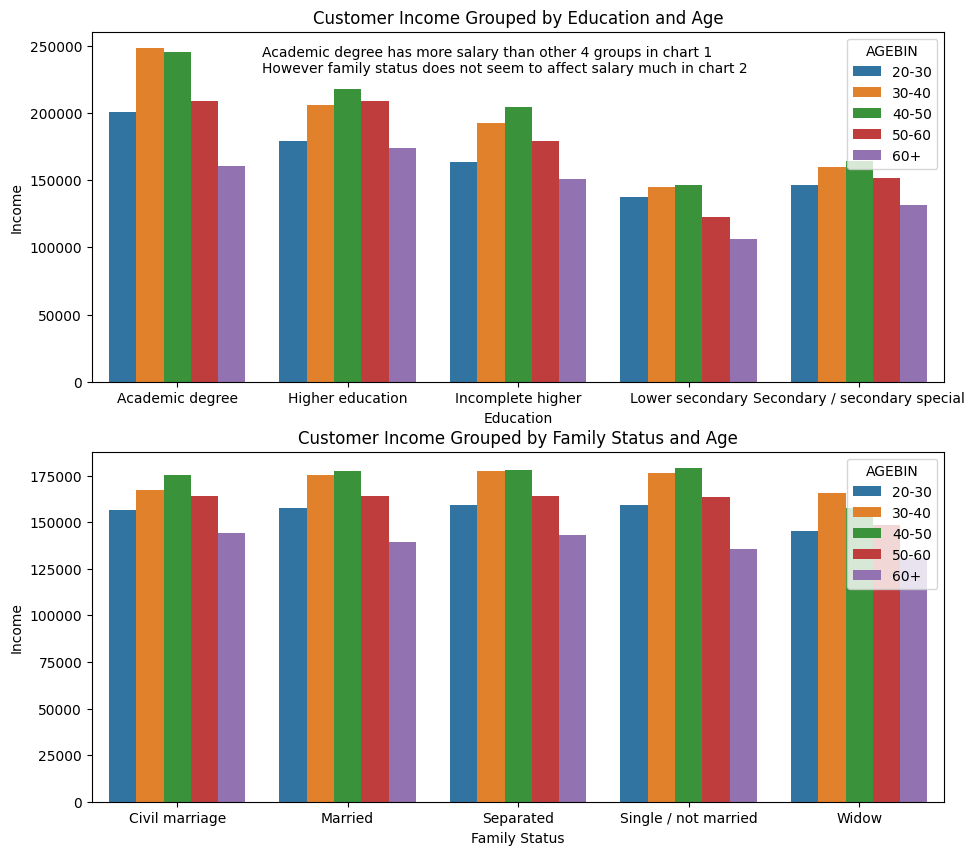

In [114]:
fig2, axs2 = plt.subplots(2, 1, figsize=(11,10))

sns.barplot(ax=axs2[0], data=df_edu_age_income, x='NAME_EDUCATION_TYPE', y='AMT_INCOME_TOTAL', hue='AGEBIN')
axs2[0].set_title('Customer Income Grouped by Education and Age')
axs2[0].set_xlabel('Education')
axs2[0].set_ylabel('Income')
axs2[0].text(0.5, 230000, ('Academic degree has more salary than other 4 groups in chart 1\n'
                         'However family status does not seem to affect salary much in chart 2'))

sns.barplot(ax=axs2[1], data=df_fam_age_income, x='NAME_FAMILY_STATUS', y='AMT_INCOME_TOTAL', hue='AGEBIN')
axs2[1].set_title('Customer Income Grouped by Family Status and Age')
axs2[1].set_xlabel('Family Status')
axs2[1].set_ylabel('Income')

### Analysis about who defaults

#### 1. gender vs trouble

In [115]:
# Who defaults or has problems replaying loans?

# we can probably drop the 4 counts of XNA since it's too small a sample
df = df[df['CODE_GENDER'] != 'XNA']
target_gender_count = df.groupby(['TARGET','CODE_GENDER'], as_index=False)['SK_ID_CURR'].count()
target_gender_count

,TARGET,CODE_GENDER,SK_ID_CURR
0,0,F,185148
1,0,M,92398
2,1,F,13956
3,1,M,10485


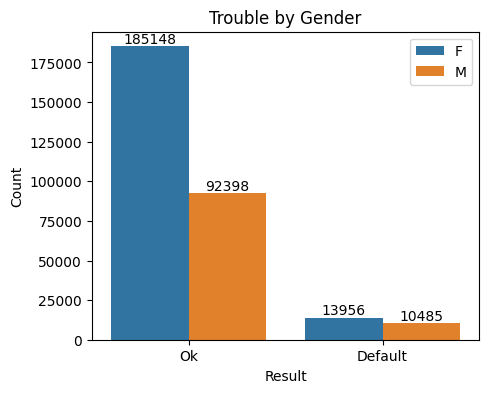

In [116]:
# in case we need to deal with single plot
# these can set figsize
# plt.rcParams['figure.figsize']=(10,10)
plt.figure(figsize=(5,4))

ax = sns.barplot(target_gender_count, x='TARGET', y='SK_ID_CURR', hue='CODE_GENDER')
ax.set_title('Trouble by Gender')
ax.set_xticks([0,1], labels=['Ok', 'Default'])
ax.set_xlabel('Result')
ax.set_ylabel('Count')
ax.bar_label(ax.containers[0], fontsize=10)
ax.bar_label(ax.containers[1], fontsize=10)
ax.legend(title=None)

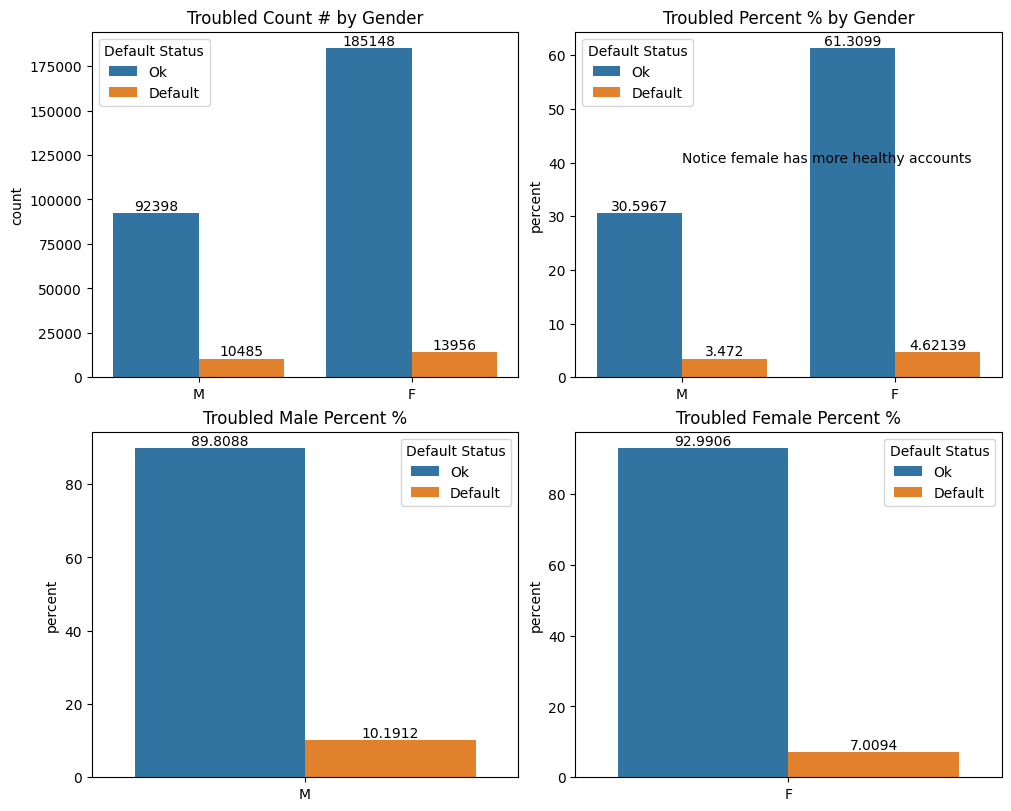

In [117]:
# actually we do not need to get a sub df first
# seaborn as a countplot that can count and group at the same time
# using the 'hue' parameter

# multi/sub plots
# for our report
fig, axs = plt.subplots(2, 2, figsize=(10,8), layout='constrained')

# each gender's user counts grouped by 'target'
sns.countplot(ax=axs[0,0], data=df, x='CODE_GENDER', hue='TARGET')
axs[0,0].set_title('Troubled Count # by Gender')

# each gender's user counts grouped by 'target', in percent
sns.countplot(ax=axs[0,1], data=df, x='CODE_GENDER', hue='TARGET', stat='percent')
axs[0,1].set_title('Troubled Percent % by Gender')
axs[0,1].text(0, 40, 'Notice female has more healthy accounts')

# male analysis
sns.countplot(ax=axs[1,0], data=df[df['CODE_GENDER'] == 'M'],
              x='CODE_GENDER', hue='TARGET', stat='percent')
axs[1,0].set_title('Troubled Male Percent %')

# female analysis
sns.countplot(ax=axs[1,1], data=df[df['CODE_GENDER'] == 'F'],
              x='CODE_GENDER', hue='TARGET', stat='percent')
axs[1,1].set_title('Troubled Female Percent %')

# this small loop adds value in text to top of bars
# also get ride of the x labels
# the M/F tick is clear enough
# touch up the legends as well for a complete report
for i in axs:
    for j in i:
        j.set_xlabel('')
        j.legend(title='Default Status', labels=['Ok', 'Default'])
        
        for o in j.containers:
            j.bar_label(o)

#### 2. car, realty, children vs trouble

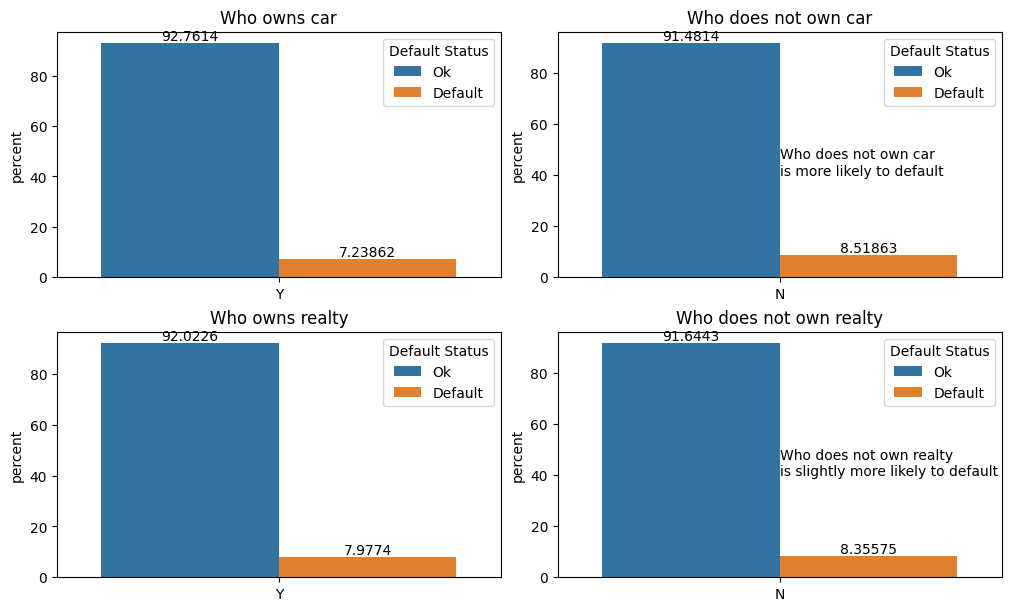

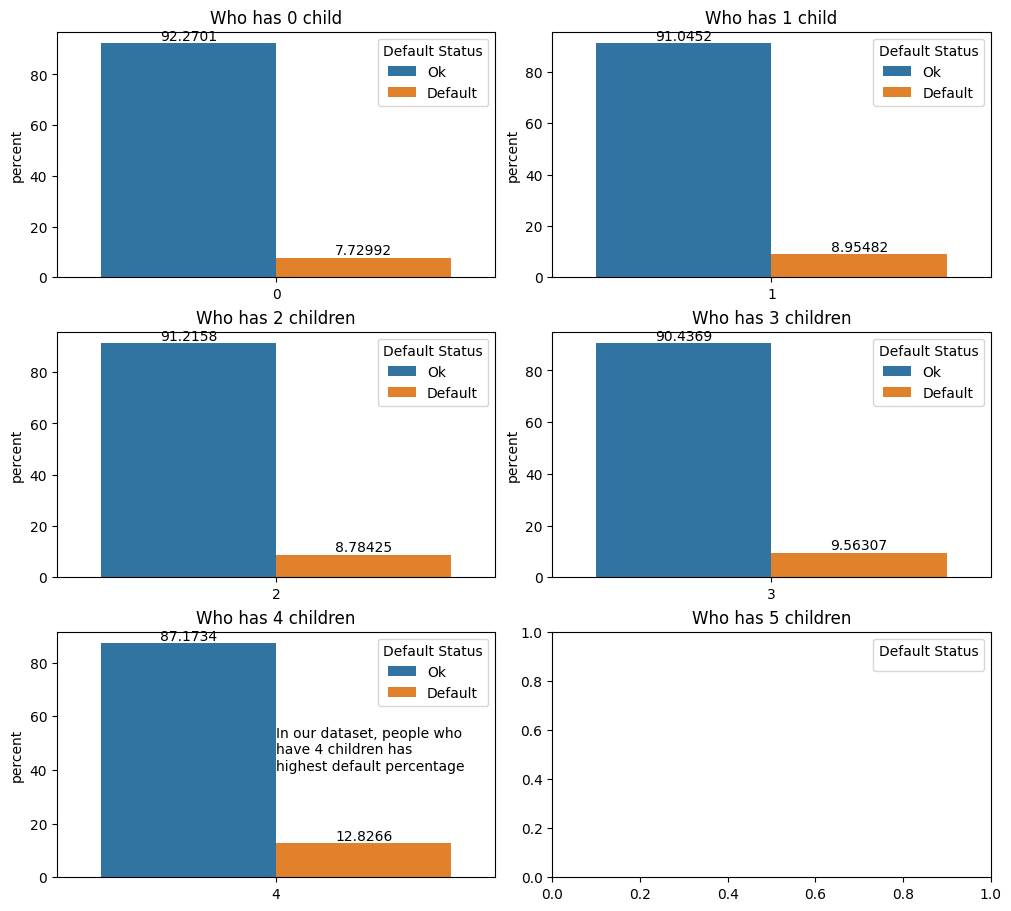

In [118]:
# 1. multi plots again
fig, axs = plt.subplots(2, 2, figsize=(10,6), layout='constrained')

# people who own car
sns.countplot(ax=axs[0,0], data=df[df['FLAG_OWN_CAR'] == 'Y'],
              x='FLAG_OWN_CAR', hue='TARGET', stat='percent')
axs[0,0].set_title('Who owns car')

# people who do not own car
sns.countplot(ax=axs[0,1], data=df[df['FLAG_OWN_CAR'] == 'N'],
              x='FLAG_OWN_CAR', hue='TARGET', stat='percent')
axs[0,1].set_title('Who does not own car')
axs[0,1].text(0, 40, 'Who does not own car\nis more likely to default')

# people who own realty
sns.countplot(ax=axs[1,0], data=df[df['FLAG_OWN_REALTY'] == 'Y'],
              x='FLAG_OWN_REALTY', hue='TARGET', stat='percent')
axs[1,0].set_title('Who owns realty')

# people who do not own realty
sns.countplot(ax=axs[1,1], data=df[df['FLAG_OWN_REALTY'] == 'N'],
              x='FLAG_OWN_REALTY', hue='TARGET', stat='percent')
axs[1,1].set_title('Who does not own realty')
axs[1,1].text(0, 40, 'Who does not own realty\nis slightly more likely to default')

# 2. second multi plots
# keep things organized
fig1, axs1 = plt.subplots(3, 2, figsize=(10,9), layout='constrained')

# does number of children have effect
sns.countplot(ax=axs1[0,0], data=df[df['CNT_CHILDREN'] == 0],
              x='CNT_CHILDREN', hue='TARGET', stat='percent')
axs1[0,0].set_title('Who has 0 child')

sns.countplot(ax=axs1[0,1], data=df[df['CNT_CHILDREN'] == 1],
              x='CNT_CHILDREN', hue='TARGET', stat='percent')
axs1[0,1].set_title('Who has 1 child')

sns.countplot(ax=axs1[1,0], data=df[df['CNT_CHILDREN'] == 2],
              x='CNT_CHILDREN', hue='TARGET', stat='percent')
axs1[1,0].set_title('Who has 2 children')

sns.countplot(ax=axs1[1,1], data=df[df['CNT_CHILDREN'] == 3],
              x='CNT_CHILDREN', hue='TARGET', stat='percent')
axs1[1,1].set_title('Who has 3 children')

sns.countplot(ax=axs1[2,0], data=df[df['CNT_CHILDREN'] == 4],
              x='CNT_CHILDREN', hue='TARGET', stat='percent')
axs1[2,0].set_title('Who has 4 children')
axs1[2,0].text(0, 40, 'In our dataset, people who\nhave 4 children has\nhighest default percentage')

sns.countplot(ax=axs1[2,1], data=df[df['CNT_CHILDREN'] == 5],
              x='CNT_CHILDREN', hue='TARGET', stat='percent')
axs1[2,1].set_title('Who has 5 children')

for i in axs:
    for j in i:
        j.set_xlabel('')
        j.legend(title='Default Status', labels=['Ok', 'Default'])
        
        for o in j.containers:
            j.bar_label(o)
            
for i in axs1:
    for j in i:
        j.set_xlabel('')
        j.legend(title='Default Status', labels=['Ok', 'Default'])
        
        for o in j.containers:
            j.bar_label(o)

#### 3. family status vs trouble

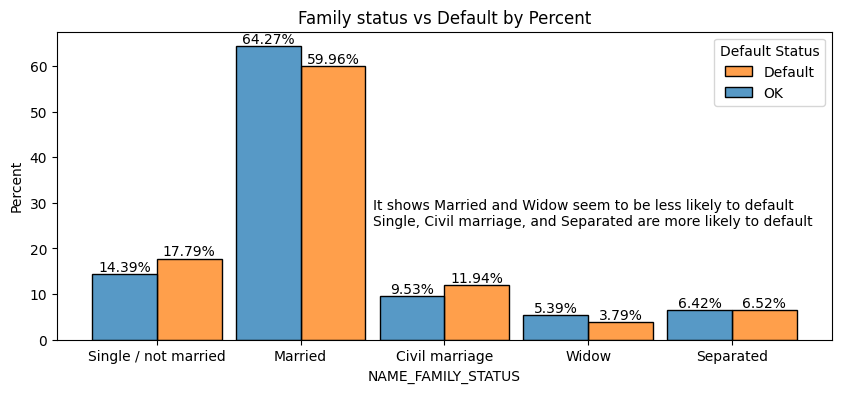

In [119]:
# it turns out we can combine all those children plots into one
# more compact, maybe harder to see all the numbers
# but it is good everything is in the same place
# we only need 1 chart

plt.rcParams['figure.figsize'] = (10,4)

h = sns.histplot(data=df, x='NAME_FAMILY_STATUS', hue='TARGET',
                 stat='percent', multiple='dodge', common_norm=False, shrink=0.9)
h.set_title('Family status vs Default by Percent')
# notice the reverse order of the labels than the countplot in above section
h.legend(title='Default Status', labels=['Default', 'OK'])
h.text(1.5, 25, ('It shows Married and Widow seem to be less likely to default\n'
                    'Single, Civil marriage, and Separated are more likely to default'))

for o in h.containers:
    h.bar_label(o, fmt='%.2f%%')

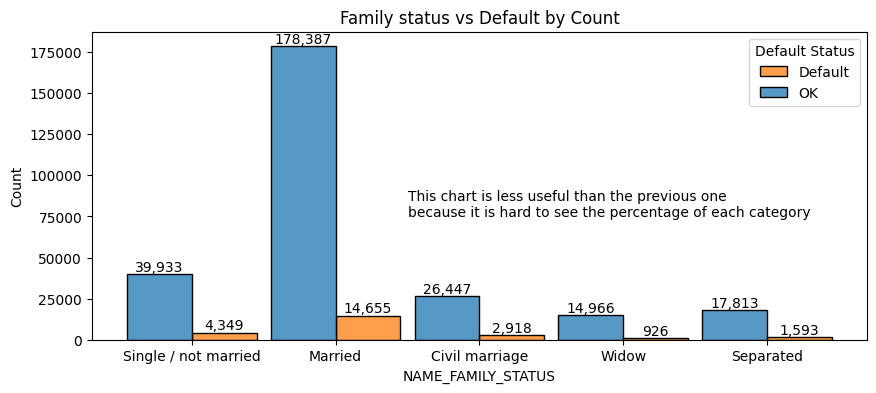

In [120]:
plt.rcParams['figure.figsize'] = (10,4)

h = sns.histplot(data=df, x='NAME_FAMILY_STATUS', hue='TARGET',
                 multiple='dodge', common_norm=False, shrink=0.9)
h.set_title('Family status vs Default by Count')
h.legend(title='Default Status', labels=['Default', 'OK'])
h.text(1.5, 75000, ('This chart is less useful than the previous one\n'
                    'because it is hard to see the percentage of each category'))

for o in h.containers:
    h.bar_label(o, fmt='{:,.0f}')

#### 4. income vs trouble

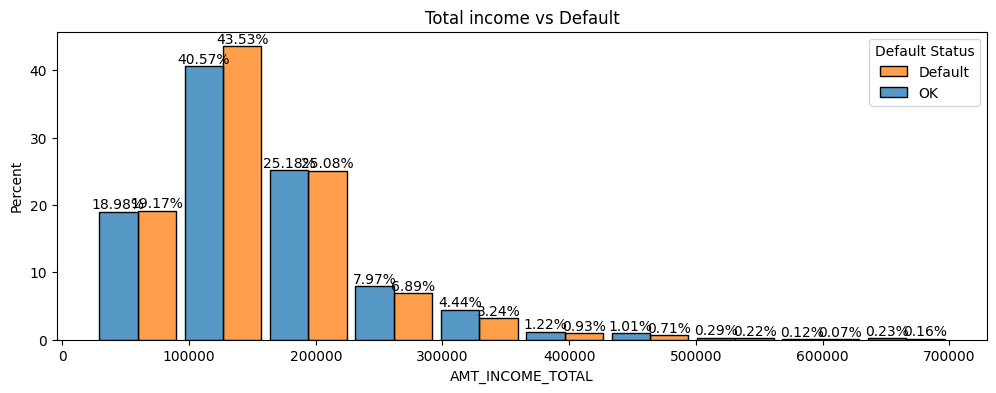

In [121]:
plt.rcParams['figure.figsize'] = (12,4)

h2 = sns.histplot(data=df, x='AMT_INCOME_TOTAL', hue='TARGET', bins=10,
                 stat='percent', multiple='dodge', common_norm=False, shrink=0.9)

h2.set_title('Total income vs Default')
h2.legend(title='Default Status', labels=['Default', 'OK'])

for o in h2.containers:
    h2.bar_label(o, fmt='{:.2f}%')

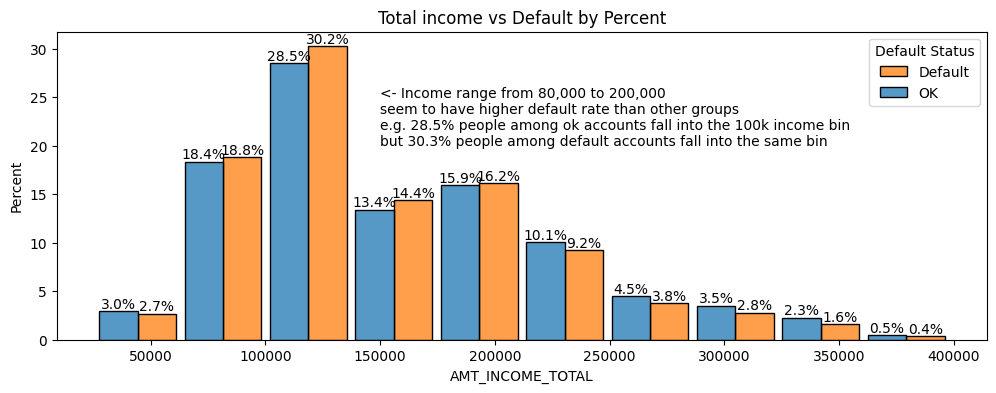

In [122]:
# the high income groups - 0.4 * 1e6 and above - are hard to see
# let's focus on the lower values

plt.rcParams['figure.figsize'] = (12,4)

h2 = sns.histplot(data=df[df['AMT_INCOME_TOTAL'] < 400000], x='AMT_INCOME_TOTAL', hue='TARGET', bins=10,
                 stat='percent', multiple='dodge', common_norm=False, shrink=0.9)

h2.set_title('Total income vs Default by Percent')
h2.legend(title='Default Status', labels=['Default', 'OK'])
h2.text(150000, 20, ('<- Income range from 80,000 to 200,000\n'
                    'seem to have higher default rate than other groups\n'
                    'e.g. 28.5% people among ok accounts fall into the 100k income bin\n'
                    'but 30.3% people among default accounts fall into the same bin'))

for o in h2.containers:
    h2.bar_label(o, fmt='{:.1f}%')

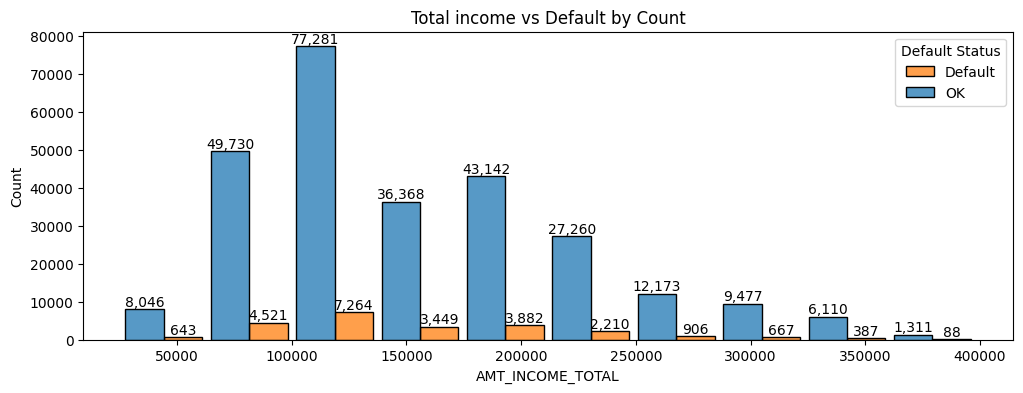

In [123]:
# check the counts

plt.rcParams['figure.figsize'] = (12,4)

h2 = sns.histplot(data=df[df['AMT_INCOME_TOTAL'] < 400000], x='AMT_INCOME_TOTAL', hue='TARGET', bins=10,
                 multiple='dodge', shrink=0.9)

h2.set_title('Total income vs Default by Count')
h2.legend(title='Default Status', labels=['Default', 'OK'])

for o in h2.containers:
    h2.bar_label(o, fmt='{:,.0f}')

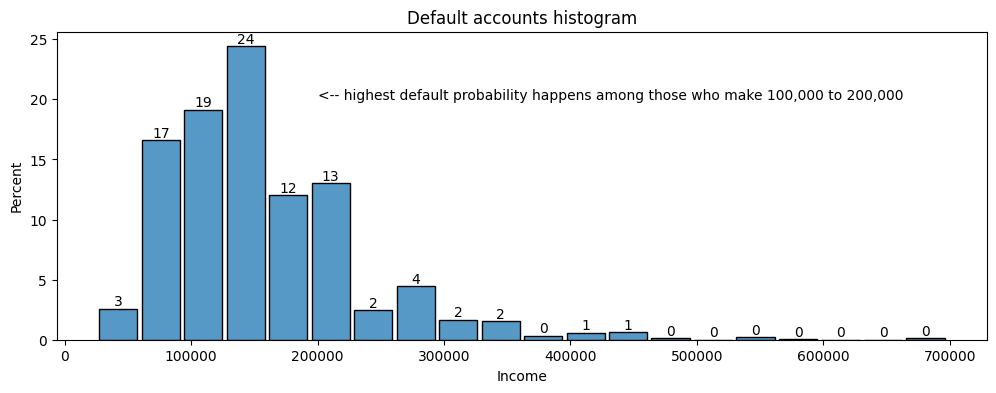

In [124]:
# show histogram of all the default accounts

plt.rcParams['figure.figsize'] = (12,4)

h2 = sns.histplot(data=df[df['TARGET'] == 1], x='AMT_INCOME_TOTAL', stat='percent', bins=20, shrink=0.9)

h2.set_title('Default accounts histogram')
h2.set_xlabel('Income')
h2.text(200000, 20, '<-- highest default probability happens among those who make 100,000 to 200,000')

for o in h2.containers:
    h2.bar_label(o, fmt='{:,.0f}')

## 5. Regression

### Logistic Regression

#### 1. data

In [125]:
# reload
df = pd.read_csv('application_train_clean.csv')

# focus on a few columns
df_sub = df.loc[:, ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
                    'AMT_ANNUITY',
                    'AGE', 'AGE_EMPLOYED', 'AGE_REGISTRATION', 'AGE_ID',
                    'AGE_CAR', 'CNT_FAM_MEMBERS']]
y = df.loc[:, 'TARGET']

len(df_sub)

301991

In [126]:
df_sub.head()

,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AGE,AGE_EMPLOYED,AGE_REGISTRATION,AGE_ID,AGE_CAR,CNT_FAM_MEMBERS
0,0,"202,500.0","406,597.5","24,700.5",25.9,1.7,10.0,5.8,-1.0,1.0
1,0,"270,000.0","1,293,502.5","35,698.5",45.9,3.3,3.2,0.8,-1.0,2.0
2,0,"67,500.0","135,000.0","6,750.0",52.2,0.6,11.7,6.9,26.0,1.0
3,0,"135,000.0","312,682.5","29,686.5",52.1,8.3,26.9,6.7,-1.0,2.0
4,0,"121,500.0","513,000.0","21,865.5",54.6,8.3,11.8,9.5,-1.0,1.0


array([[<Axes: title={'center': 'CNT_CHILDREN'}>,
        <Axes: title={'center': 'AMT_INCOME_TOTAL'}>,
        <Axes: title={'center': 'AMT_CREDIT'}>],
       [<Axes: title={'center': 'AMT_ANNUITY'}>,
        <Axes: title={'center': 'AGE'}>,
        <Axes: title={'center': 'AGE_EMPLOYED'}>],
       [<Axes: title={'center': 'AGE_REGISTRATION'}>,
        <Axes: title={'center': 'AGE_ID'}>,
        <Axes: title={'center': 'AGE_CAR'}>],
       [<Axes: title={'center': 'CNT_FAM_MEMBERS'}>, <Axes: >, <Axes: >]],
      dtype=object)

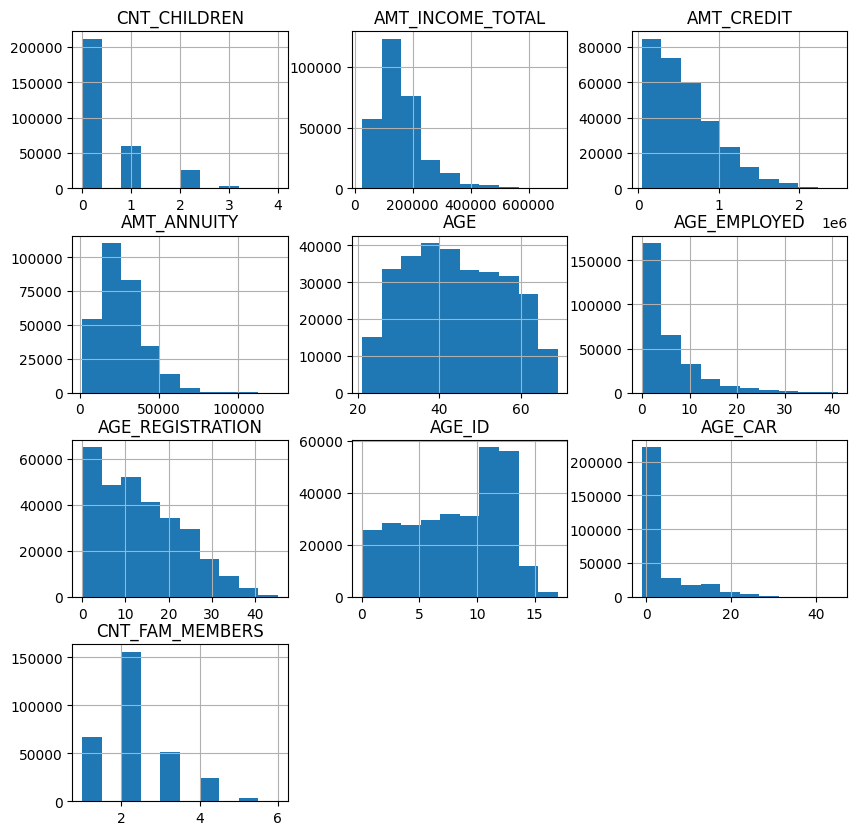

In [127]:
df_sub.hist(figsize=(10,10))

In [128]:
# fit LogisticRegression without feature names
# easier for later prediction part
# no warnings
df_sub_values = df_sub.values
df_sub_values.shape

(301991, 10)

In [129]:
len(y)

301991

In [130]:
y.head()

0    1
1    0
2    0
3    0
4    0
Name: TARGET, dtype: int64

In [131]:
y.shape

(301991,)

In [132]:
lr = LogisticRegression(class_weight='balanced')

lr.fit(df_sub_values, y)

LogisticRegression(class_weight='balanced')

#### 2. scoring and confusion matrix

In [133]:
lr.score(df_sub_values, y)

0.7086800600017882

In [134]:
predict_test = lr.predict(df_sub_values)

np.unique(predict_test, return_counts=True)

(array([0, 1], dtype=int64), array([221954,  80037], dtype=int64))

In [135]:
y.value_counts()

TARGET
0    277550
1     24441
Name: count, dtype: int64

In [136]:
from sklearn.metrics import confusion_matrix

df_cm = pd.DataFrame(confusion_matrix(y, predict_test))

df_cm = df_cm.rename(columns={0: 'pred no', 1: 'pred yes'},
                     index={0: 'actual no', 1: 'actual yes'}
                    )
df_cm

,pred no,pred yes
actual no,205764,71786
actual yes,16190,8251


#### 3. predict

In [137]:
# lr was trained by 301991 records
# score 0.7086800600017882

# try to predict with some made-up independent varaible
# this is the template

X = pd.DataFrame([[0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]],
                 columns=['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
                          'AMT_ANNUITY',
                          'AGE', 'AGE_EMPLOYED', 'AGE_REGISTRATION', 'AGE_ID',
                          'AGE_CAR', 'CNT_FAM_MEMBERS']
                )

# this is from the head of the training dataset
a = [0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]
b = np.array(a).reshape(1, -1)

lr.predict_proba(b)

array([[0.55818112, 0.44181888]])

In [138]:
# this one actualy predicts correctly
# 55.8% probability points to 0
y[2]

0

In [139]:
# now let's check each independent variable
# CNT_CHILDREN
# no effect
a = [0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(7):
    a[0] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[0] [[0.55818112 0.44181888]]
[0] [[0.55814823 0.44185177]]
[0] [[0.55811533 0.44188467]]
[0] [[0.55808243 0.44191757]]
[0] [[0.55804953 0.44195047]]
[0] [[0.55801663 0.44198337]]
[0] [[0.55798372 0.44201628]]


In [140]:
# AMT_INCOME_TOTAL
# more income, more likely to default
# ?? not common sense
# just slightly though
a = [0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(0, 500000, 50000):
    a[1] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[0] [[0.56061684 0.43938316]]
[0] [[0.55881288 0.44118712]]
[0] [[0.55700737 0.44299263]]
[0] [[0.55520035 0.44479965]]
[0] [[0.55339187 0.44660813]]
[0] [[0.55158198 0.44841802]]
[0] [[0.54977071 0.45022929]]
[0] [[0.54795813 0.45204187]]
[0] [[0.54614428 0.45385572]]
[0] [[0.5443292 0.4556708]]


In [141]:
# AMT_CREDIT
# more credit, less likely to default
# don't know
a = [0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(0, 1500000, 100000):
    a[2] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[0] [[0.54186499 0.45813501]]
[0] [[0.55396162 0.44603838]]
[0] [[0.56599467 0.43400533]]
[0] [[0.57795042 0.42204958]]
[0] [[0.5898155 0.4101845]]
[0] [[0.60157697 0.39842303]]
[0] [[0.61322235 0.38677765]]
[0] [[0.62473967 0.37526033]]
[0] [[0.63611755 0.36388245]]
[0] [[0.64734518 0.35265482]]
[0] [[0.65841241 0.34158759]]
[0] [[0.66930975 0.33069025]]
[0] [[0.68002839 0.31997161]]
[0] [[0.69056022 0.30943978]]
[0] [[0.70089788 0.29910212]]


In [142]:
# AMT_ANNUITY
# more annuity, more likely to default
# sounds about right
a = [0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(0, 50000, 5000):
    a[3] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[0] [[0.58624847 0.41375153]]
[0] [[0.56550117 0.43449883]]
[0] [[0.54452181 0.45547819]]
[0] [[0.52338323 0.47661677]]
[0] [[0.50216055 0.49783945]]
[1] [[0.48093008 0.51906992]]
[1] [[0.45976825 0.54023175]]
[1] [[0.4387505 0.5612495]]
[1] [[0.41795023 0.58204977]]
[1] [[0.39743778 0.60256222]]


In [143]:
# AGE
# older, less likely to default
a = [0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(0, 70, 5):
    a[4] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[1] [[0.49391628 0.50608372]]
[0] [[0.50009701 0.49990299]]
[0] [[0.5062777 0.4937223]]
[0] [[0.51245648 0.48754352]]
[0] [[0.51863145 0.48136855]]
[0] [[0.52480073 0.47519927]]
[0] [[0.53096246 0.46903754]]
[0] [[0.53711476 0.46288524]]
[0] [[0.54325577 0.45674423]]
[0] [[0.54938367 0.45061633]]
[0] [[0.55549663 0.44450337]]
[0] [[0.56159283 0.43840717]]
[0] [[0.56767049 0.43232951]]
[0] [[0.57372785 0.42627215]]


In [144]:
# AGE_EMPLOYED
# not much difference
a = [0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(0, 40, 5):
    a[5] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[0] [[0.55788722 0.44211278]]
[0] [[0.56033515 0.43966485]]
[0] [[0.56278016 0.43721984]]
[0] [[0.56522211 0.43477789]]
[0] [[0.5676609 0.4323391]]
[0] [[0.57009642 0.42990358]]
[0] [[0.57252855 0.42747145]]
[0] [[0.57495718 0.42504282]]


In [145]:
# AGE_REGISTRATION
# not much effect
a = [0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(0, 40, 5):
    a[6] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[0] [[0.55090057 0.44909943]]
[0] [[0.55401477 0.44598523]]
[0] [[0.55712474 0.44287526]]
[0] [[0.56023024 0.43976976]]
[0] [[0.56333103 0.43666897]]
[0] [[0.56642687 0.43357313]]
[0] [[0.56951754 0.43048246]]
[0] [[0.57260281 0.42739719]]


In [146]:
# AGE_CAR
# no effect
a = [0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(0, 50, 5):
    a[7] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[0] [[0.55600536 0.44399464]]
[0] [[0.55758222 0.44241778]]
[0] [[0.55915792 0.44084208]]
[0] [[0.56073243 0.43926757]]
[0] [[0.56230572 0.43769428]]
[0] [[0.56387775 0.43612225]]
[0] [[0.56544851 0.43455149]]
[0] [[0.56701795 0.43298205]]
[0] [[0.56858604 0.43141396]]
[0] [[0.57015276 0.42984724]]


In [147]:
# CNT_FAM_MEMBERS
# no effect
a = [0, 67500, 135000, 6750, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(8):
    a[8] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[0] [[0.5593935 0.4406065]]
[0] [[0.55934688 0.44065312]]
[0] [[0.55930027 0.44069973]]
[0] [[0.55925365 0.44074635]]
[0] [[0.55920703 0.44079297]]
[0] [[0.55916041 0.44083959]]
[0] [[0.55911378 0.44088622]]
[0] [[0.55906716 0.44093284]]


In [148]:
# the first try has a good score of 0.71
# however it is not satisfactory
# because most of the age columns do not seem to matter
# or has an effect that is too small to change the final outcome from 0 to 1
# which is big
# let's try again

### Logistic Regression second version

#### 1. second version

In [149]:
# focus on fewer columns
# we suspect the money ones have too wide a range
# and the age ones has too narrow a range
# 0-70 is nothing compared to 0-1million

df_less = df_sub.drop(columns=['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY'])

y = df['TARGET']

df_less, y

(        CNT_CHILDREN  AGE  AGE_EMPLOYED  AGE_REGISTRATION  AGE_ID  AGE_CAR  \
 0                  0 25.9           1.7              10.0     5.8     -1.0   
 1                  0 45.9           3.3               3.2     0.8     -1.0   
 2                  0 52.2           0.6              11.7     6.9     26.0   
 3                  0 52.1           8.3              26.9     6.7     -1.0   
 4                  0 54.6           8.3              11.8     9.5     -1.0   
 ...              ...  ...           ...               ...     ...      ...   
 301986             0 25.6           0.6              23.2     5.4     -1.0   
 301987             0 56.9          -0.0              12.0    11.2     -1.0   
 301988             0 41.0          21.7              18.5    14.1     -1.0   
 301989             0 32.8          13.1               7.0     2.6     -1.0   
 301990             0 46.2           3.5              14.0     1.1     -1.0   
 
         CNT_FAM_MEMBERS  
 0                   1.

array([[<Axes: title={'center': 'CNT_CHILDREN'}>,
        <Axes: title={'center': 'AGE'}>,
        <Axes: title={'center': 'AGE_EMPLOYED'}>],
       [<Axes: title={'center': 'AGE_REGISTRATION'}>,
        <Axes: title={'center': 'AGE_ID'}>,
        <Axes: title={'center': 'AGE_CAR'}>],
       [<Axes: title={'center': 'CNT_FAM_MEMBERS'}>, <Axes: >, <Axes: >]],
      dtype=object)

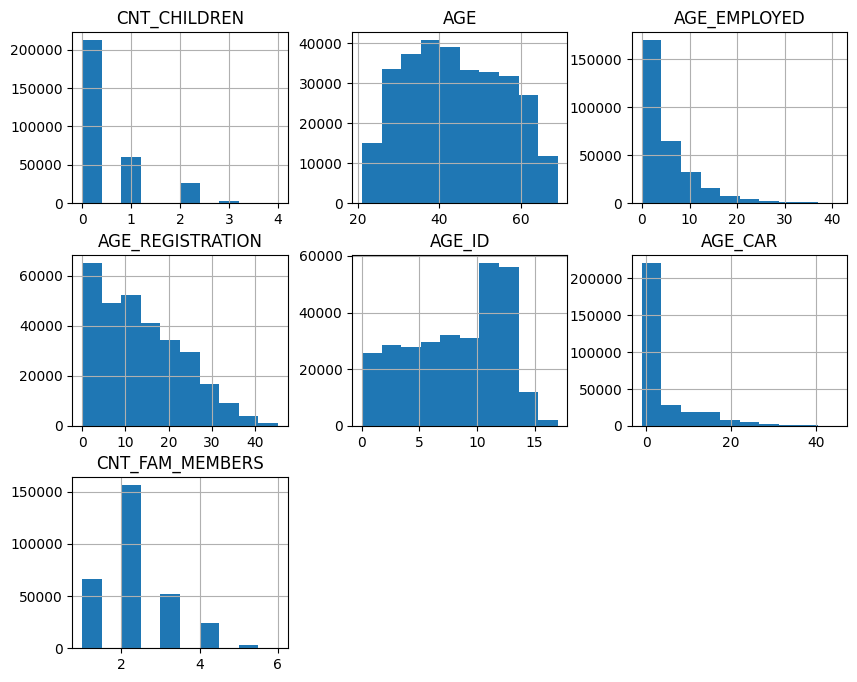

In [150]:
df_less.hist(figsize=(10,8))

In [151]:
lr = LogisticRegression(class_weight='balanced')

lr.fit(df_less.values, y)

lr.score(df_less.values, y)

0.5742224106016405

In [152]:
test = lr.predict(df_less.values)

np.unique(test, return_counts=True)

(array([0, 1], dtype=int64), array([169163, 132828], dtype=int64))

#### 2. predict

In [153]:
# lr was trained by 301991 records
# score 0.5742224106016405

# this is the template of input

X = pd.DataFrame([[0, 52.2, 0.6, 11.7, 6.9, 26.0, 1]],
                 columns=['CNT_CHILDREN', 'AGE', 'AGE_EMPLOYED',
                          'AGE_REGISTRATION', 'AGE_ID',
                          'AGE_CAR', 'CNT_FAM_MEMBERS']
                )

# this is from the head of the training dataset
a = [0, 52.2, 0.6, 11.7, 6.9, 26.0, 1]
b = np.array(a).reshape(1, -1)

lr.predict_proba(b)

array([[0.4946436, 0.5053564]])

In [154]:
# CNT_CHILDREN
# here we go
# looks like we guessed the right thing by dropping the money columns
# now we can see the differences of outcomes if we change CNT_CHILDREN
# more children, more likely to default
a = [0, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(8):
    a[0] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[1] [[0.4946436 0.5053564]]
[1] [[0.47304373 0.52695627]]
[1] [[0.45154429 0.54845571]]
[1] [[0.43022422 0.56977578]]
[1] [[0.40915982 0.59084018]]
[1] [[0.38842368 0.61157632]]
[1] [[0.36808375 0.63191625]]
[1] [[0.3482025 0.6517975]]


In [155]:
# AGE
# better than first version as now we can see the difference among age groups
# older, less likely to default
a = [0, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(0, 77, 5):
    a[1] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[1] [[0.252991 0.747009]]
[1] [[0.27268021 0.72731979]]
[1] [[0.29330011 0.70669989]]
[1] [[0.31480438 0.68519562]]
[1] [[0.33713316 0.66286684]]
[1] [[0.3602131 0.6397869]]
[1] [[0.38395786 0.61604214]]
[1] [[0.40826902 0.59173098]]
[1] [[0.43303746 0.56696254]]
[1] [[0.45814513 0.54185487]]
[1] [[0.48346718 0.51653282]]
[0] [[0.50887442 0.49112558]]
[0] [[0.53423589 0.46576411]]
[0] [[0.5594216 0.4405784]]
[0] [[0.58430512 0.41569488]]
[0] [[0.60876611 0.39123389]]


In [156]:
# AGE_EMPLOYED
# slight increase in account's realiability as holder's work age increase
a = [0, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(0, 40, 5):
    a[3] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[1] [[0.47371657 0.52628343]]
[1] [[0.48265274 0.51734726]]
[1] [[0.49160001 0.50839999]]
[0] [[0.50055267 0.49944733]]
[0] [[0.50950498 0.49049502]]
[0] [[0.51845119 0.48154881]]
[0] [[0.52738559 0.47261441]]
[0] [[0.53630248 0.46369752]]


In [157]:
# CNT_FAM_MEMBERS
# more family members, less likely to default
a = [0, 52.2, 0.6, 11.7, 6.9, 26.0, 1]

for i in range(8):
    a[6] = i
    b = np.array(a).reshape(1, -1)
    print(lr.predict(b), lr.predict_proba(b))

[1] [[0.47362801 0.52637199]]
[1] [[0.4946436 0.5053564]]
[0] [[0.51567814 0.48432186]]
[0] [[0.53665727 0.46334273]]
[0] [[0.55750743 0.44249257]]
[0] [[0.57815686 0.42184314]]
[0] [[0.59853658 0.40146342]]
[0] [[0.61858126 0.38141874]]


In [158]:
# conclusion
# the second version is not complete because it omits those money columns
# like income, amount of credit etc
# however it is very useful for us to see the difference of outcome
# from changing those age columns

#### 3. plot

<Axes: >

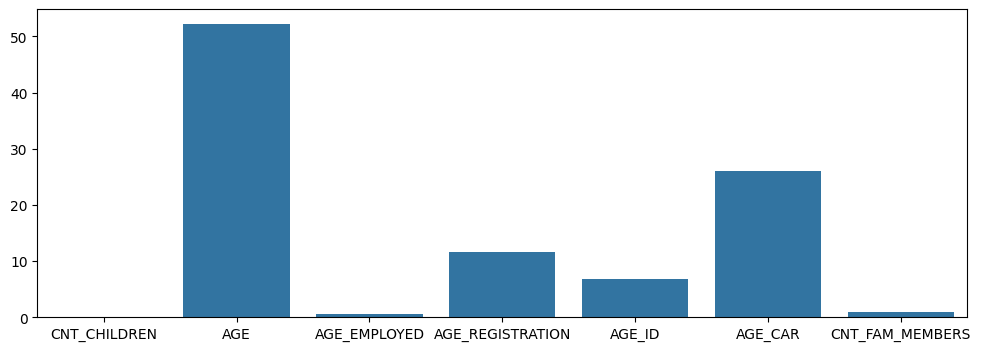

In [159]:
# finally some plot to show the prediction visually

# this is our reference applicant, 'Joe'
# [0, 52.2, 0.6, 11.7, 6.9, 26.0, 1]
# 0 children
# 52.2 years old
# 0.6 years of being employed
# 11.7 years of latest registration
# 6.9 years of latest ID
# with a car of 26 years old
# and a family member of 1

sns.barplot(x=['CNT_CHILDREN', 'AGE', 'AGE_EMPLOYED',
               'AGE_REGISTRATION', 'AGE_ID',
               'AGE_CAR', 'CNT_FAM_MEMBERS'],
            y=[0, 52.2, 0.6, 11.7, 6.9, 26.0, 1])

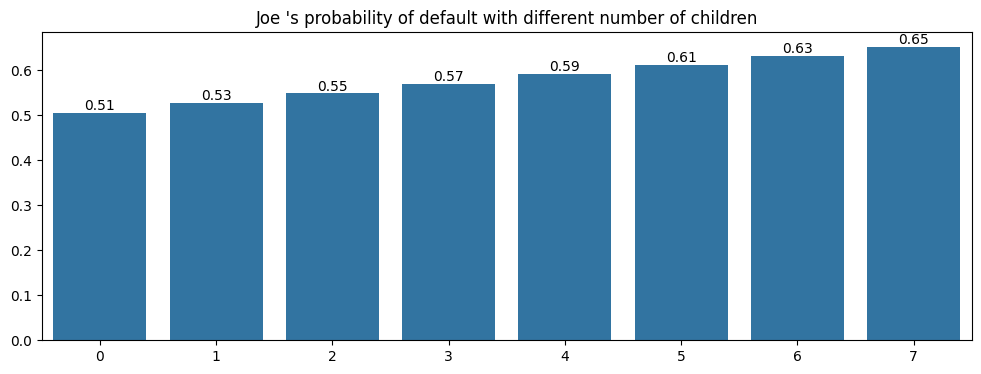

In [160]:
# what if we change some of the inputs?

a = [0, 52.2, 0.6, 11.7, 6.9, 26.0, 1]
x_list = []
y_list = []

for i in range(8):
    a[0] = i
    b = np.array(a).reshape(1, -1)
    
    x_list.append(i)
    y_list.append(lr.predict_proba(b)[0][1])

ax = sns.barplot(x=x_list, y=y_list)
ax.set_title('Joe \'s probability of default with different number of children')
for o in ax.containers:
    ax.bar_label(o, fmt='%.2f')

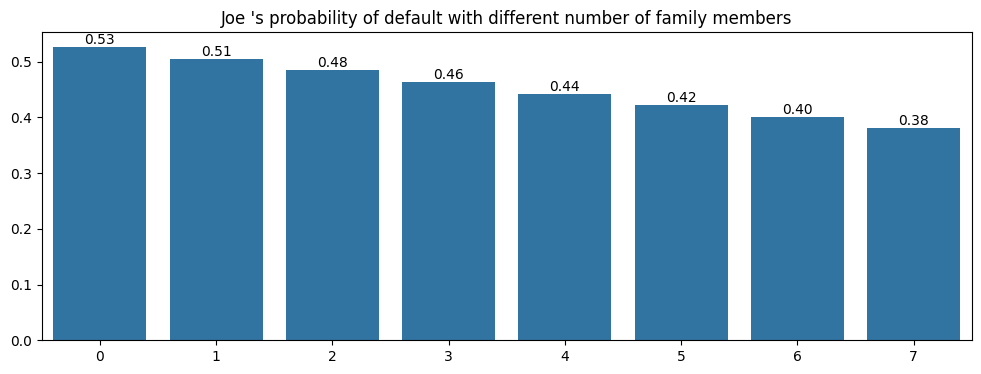

In [161]:
a = [0, 52.2, 0.6, 11.7, 6.9, 26.0, 1]
x_list = []
y_list = []

for i in range(8):
    a[6] = i
    b = np.array(a).reshape(1, -1)
    
    x_list.append(i)
    y_list.append(lr.predict_proba(b)[0][1])

ax = sns.barplot(x=x_list, y=y_list, errorbar=None)
ax.set_title('Joe \'s probability of default with different number of family members')
for o in ax.containers:
    ax.bar_label(o, fmt='%.2f')

In [162]:
# end of project